# Quiver Representations for Graph Analysis

**CIARP 2026 hands-on workshop** · Carlos Isaac Zainea Maya and Agustín Moreno Cañadas · Universidad Nacional de Colombia

This notebook follows the slides block by block. Every example is either a small hand-made quiver or a **simulated network** generated with a fixed seed, so nothing is downloaded and every number can be reproduced.

| Block in the slides | Section here | What you run |
|---|---|---|
| 01 · An applied process | [1](#1) | Reachability on a six-node network, with and without the bridge |
| 02 · From graphs to algebra | [2](#2) | Paths, the path algebra, relations and a representation of the diamond |
| 03 · Dynamics on a quiver | [3](#3) | An impact automaton on a simulated network, and path-based multi-hop support |
| 04 · Brauer configurations | [4](#4) | Brauer configurations by hand, then on simulated citation corpora |
| Extension | [5](#5) | Optional: train GAT, a walk operator and Walk Attention on a synthetic task |

**Convention used everywhere:** paths are written left to right, so `ab` means first `a`, then `b`.

**How to work with it:** predict first, then run. Cells titled **Try it** have sliders and boxes: move them and watch what changes. Cells titled **Check yourself** verify your answer without showing it.

## 0. Setup

In [1]:
!pip install -q aiq-quivers

In [ ]:
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import aiq
from aiq import Quiver, PathAlgebra, Ideal, QuotientAlgebra, AIQ, BrauerConfiguration

print("aiq-quivers", aiq.__version__)


def draw_quiver(Q, pos=None, title=None, colors=None, highlight=(), labels=True,
                node_size=900, figsize=(6, 4), seed=1):
    # Draw a quiver: parallel and opposite arrows are bent so that all of them are visible.
    G = nx.DiGraph()
    G.add_nodes_from(Q.Q0)
    G.add_edges_from((s, t) for _, s, t in Q.Q1)
    if pos is None:
        pos = nx.spring_layout(G, seed=seed)
    fig, ax = plt.subplots(figsize=figsize)
    node_colors = [(colors or {}).get(v, "white") for v in Q.Q0]
    nx.draw_networkx_nodes(G, pos, nodelist=list(Q.Q0), node_color=node_colors,
                           edgecolors="black", node_size=node_size, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)
    pairs = [(s, t) for _, s, t in Q.Q1]
    seen = {}
    for name, s, t in Q.Q1:
        k = seen.get((s, t), 0)
        seen[(s, t)] = k + 1
        bend = 0.0 if (k == 0 and (t, s) not in pairs) else 0.22 + 0.2 * k
        red = name in highlight
        nx.draw_networkx_edges(G, pos, edgelist=[(s, t)], ax=ax, node_size=node_size,
                               connectionstyle=f"arc3,rad={bend}", arrowsize=16,
                               edge_color="#E00234" if red else "#555555",
                               width=2.4 if red else 1.4)
        if labels and s != t:
            (x1, y1), (x2, y2) = pos[s], pos[t]
            ax.text((x1 + x2) / 2 + bend * (y2 - y1) / 2, (y1 + y2) / 2 - bend * (x2 - x1) / 2,
                    str(name), fontsize=10, style="italic", ha="center", va="center",
                    bbox=dict(fc="white", ec="none", pad=0.5))
    ax.set_title(title or "")
    ax.axis("off")
    plt.show()


# Sliders for the 'Try it' cells and the checker for the 'Check yourself' cells.
import hashlib
from IPython.display import display

try:
    from ipywidgets import interact, IntSlider, FloatSlider, Checkbox, Dropdown, Text
    WIDGETS = True
except Exception:                      # no widgets here: every "Try it" cell still runs once, with its default values
    WIDGETS = False

    class _Fixed:
        def __init__(self, value=None, options=None, **_):
            self.value = value if value is not None or not options else list(options)[0]

    IntSlider = FloatSlider = Checkbox = Dropdown = Text = _Fixed

    def interact(function, **controls):
        function(**{name: c.value for name, c in controls.items() if isinstance(c, _Fixed)})
        print("(No sliders in this environment: change the default values in the function and run the cell again.)")

_ANSWERS = {
    'nodes reached without the bridge': ('4b227777d4dd1fc6', 'Count A and everything A can reach when D → E is missing.'),
    'paths of length two in the diamond': ('d4735e3a265e16ee', 'Both go from A to D.'),
    'dimension after removing the arrow b': ('2c624232cdd22177', 'You lose the arrow b and the path ab.'),
    'dimension with ab = cd': ('19581e27de7ced00', 'Two basis elements become one.'),
    'node reached from A with exactly three hops': ('a9f51566bd6705f7', 'Follow A → B → D → ... in the five-node network.'),
    'pairs gained at range 6 thanks to the bridge': ('81b8a03f97e8787c', 'Subtract the two columns of the last row.'),
    'arrows of the four-polygon quiver': ('2c624232cdd22177', 'Add the valencies of the vertices that are not truncated.'),
    'dimension of the four-polygon algebra': ('9400f1b21cb527d7', '2 · 4 plus the sum of val · (μ · val − 1).'),
    'dimension of the centre when P3 also cites d': ('ef2d127de37b942b', '1 + h + |C|, and now only e is cited once.'),
}


def check(question, answer):
    # Compare your answer with the expected one, without showing it.
    if answer is ...:
        print(f"[ ] {question}: write your answer in place of the three dots.")
        return
    expected, hint = _ANSWERS[question]
    if hashlib.sha256(str(answer).strip().upper().encode()).hexdigest()[:16] == expected:
        print(f"[✓] {question}: correct.")
    else:
        print(f"[✗] {question}: not yet. Hint: {hint}")


print("Ready: cells marked 'Try it' have sliders, cells marked 'Check yourself' verify your answers.")

aiq-quivers 1.2.1
Ready: cells marked 'Try it' have sliders, cells marked 'Check yourself' verify your answers.


<a id="1"></a>
## 1. An applied process

*Slides: "Propagation on a network with one bridge" and "What a model must specify and test".*

A signal spreads through a contact network. At each step an active node activates its outgoing neighbours, and an active node stays active. This is a deterministic teaching toy: there is no infection rate, no recovery and no calibration.

**Before running the cell, predict** which nodes will be reached from A. Then predict again without the bridge D → E.

t = 0: A
t = 1: A B C
t = 2: A B C D
t = 3: A B C D E
t = 4: A B C D E F


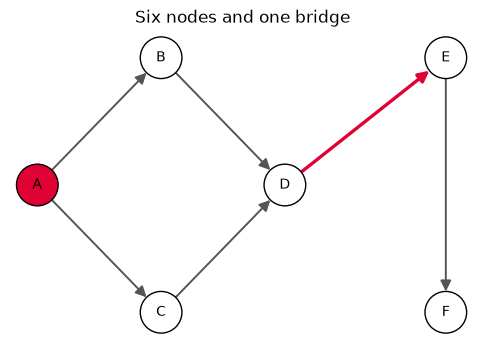

In [3]:
arrows = [("ab", "A", "B"), ("ac", "A", "C"), ("bd", "B", "D"),
          ("cd", "C", "D"), ("bridge", "D", "E"), ("ef", "E", "F")]
Q_toy = Quiver(list("ABCDEF"), arrows)
pos_toy = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0), "E": (3.3, 1), "F": (3.3, -1)}


def spread(Q, seeds, steps=6):
    # Deterministic, persistent activation along the arrows.
    active = set(seeds)
    history = [sorted(active)]
    for _ in range(steps):
        new = active | {t for _, s, t in Q.Q1 if s in active}
        if new == active:
            break
        active = new
        history.append(sorted(active))
    return history


for t, a in enumerate(spread(Q_toy, ["A"])):
    print(f"t = {t}: {' '.join(a)}")
draw_quiver(Q_toy, pos_toy, "Six nodes and one bridge", colors={"A": "#E00234"},
            highlight=["bridge"], labels=False)

In [4]:
Q_cut = Quiver(list("ABCDEF"), [a for a in arrows if a[0] != "bridge"])
for t, a in enumerate(spread(Q_cut, ["A"])):
    print(f"t = {t}: {' '.join(a)}")
print("\nNever reached without the bridge:",
      sorted(set("ABCDEF") - set(spread(Q_cut, ["A"])[-1])))

t = 0: A
t = 1: A B C
t = 2: A B C D

Never reached without the bridge: ['E', 'F']


#### Picture: the news, step by step

Top row with the bridge, bottom row without it. Red nodes already know the news; red arrows are the ones the news crosses in that step. The two rows are equal until step 2. At step 3 the top row crosses the bridge and the bottom row has nowhere to go.

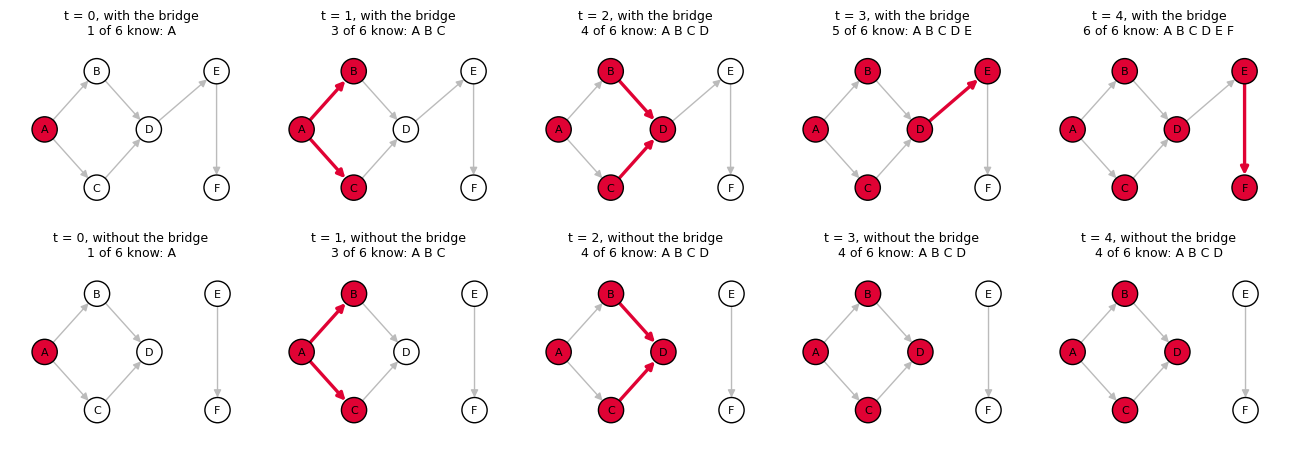

In [ ]:
def small_quiver(ax, Q, pos, red_arrows=(), red_nodes=(), title="", numbers=None, node_size=330,
                 blue_arrows=()):
    # A small drawing of a quiver, to be placed in a row of pictures.
    G = nx.DiGraph()
    G.add_nodes_from(Q.Q0)
    G.add_edges_from((s, t) for _, s, t in Q.Q1)
    nx.draw_networkx_nodes(G, pos, nodelist=list(Q.Q0), ax=ax, node_size=node_size, edgecolors="black",
                           node_color=["#E00234" if v in red_nodes else "white" for v in Q.Q0])
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    for name, s, t in Q.Q1:
        color = "#E00234" if name in red_arrows else "#1F77B4" if name in blue_arrows else "#BBBBBB"
        nx.draw_networkx_edges(G, pos, edgelist=[(s, t)], ax=ax, node_size=node_size, arrowsize=11,
                               edge_color=color, width=1.0 if color == "#BBBBBB" else 2.4)
        if numbers:
            (x1, y1), (x2, y2) = pos[s], pos[t]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{name} = {numbers[name]}", fontsize=8, ha="center",
                    va="center", bbox=dict(fc="white", ec="none", pad=0.4))
    ax.set_title(title, fontsize=9)
    ax.margins(0.18)
    ax.axis("off")


fig, axes = plt.subplots(2, 5, figsize=(13, 4.6))
for row_axes, (Q, label) in zip(axes, ((Q_toy, "with the bridge"), (Q_cut, "without the bridge"))):
    history = spread(Q, ["A"])
    for t, ax in enumerate(row_axes):
        now = set(history[min(t, len(history) - 1)])
        before = set(history[min(max(t - 1, 0), len(history) - 1)])
        crossing = [name for name, s, v in Q.Q1 if s in before and v in now - before]
        small_quiver(ax, Q, pos_toy, red_nodes=now, red_arrows=crossing,
                     title=f"t = {t}, {label}\n{len(now)} of 6 know: {' '.join(sorted(now))}")
plt.tight_layout()
plt.show()

#### Try it: move the news one step at a time

Move the slider to advance one step. Switch the bridge off and start again. **Before you move it:** at which step do the two versions stop being equal?

In [ ]:
def show_spread(step=0, bridge=True):
    Q = Q_toy if bridge else Q_cut
    history = spread(Q, ["A"])
    active = history[min(step, len(history) - 1)]
    draw_quiver(Q, pos_toy, f"step {step}: {len(active)} of 6 nodes know the news",
                colors={v: "#E00234" for v in active}, highlight=["bridge"], labels=False)


interact(show_spread, step=IntSlider(value=0, min=0, max=5),
         bridge=Checkbox(value=True, description="bridge D → E"));

#### Check yourself

Replace the three dots with your answer and run the cell.

In [ ]:
check("nodes reached without the bridge", ...)

Removing one arrow changed the result. To get an answer we had to specify: the state of a node, what makes an interaction possible, what changes at each step, and which quantity we measure.

<a id="2"></a>
## 2. From graphs to algebra

*Slides: "Quivers" to "Representations of a quiver".*

A quiver is $Q = (Q_0, Q_1, s, t)$: vertices, arrows, and the source and target of each arrow. The **diamond** has two routes from A to D.

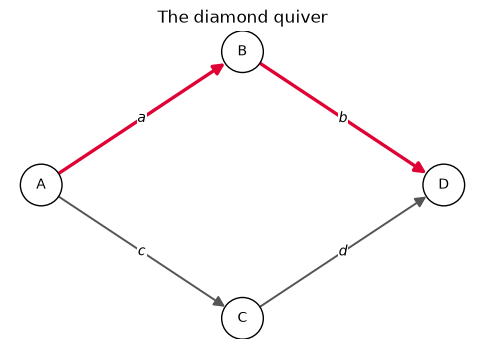

In [5]:
diamond = Quiver(list("ABCD"), [("a", "A", "B"), ("b", "B", "D"), ("c", "A", "C"), ("d", "C", "D")])
pos_d = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0)}
draw_quiver(diamond, pos_d, "The diamond quiver", highlight=["a", "b"])

### Exercise: list every basis path

Include the paths of length zero, one at each vertex. How many paths have length two? Can a path have length three? Answer on paper first, then run the cell.

In [6]:
kQ = PathAlgebra(diamond)
for length in range(4):
    paths = kQ.enumerate_paths(length)
    print(f"length {length}: {len(paths)} path(s)  ", [str(p) for p in paths])
print("\ndim KQ =", kQ.total_dimension())

length 0: 4 path(s)   ['e_A', 'e_B', 'e_C', 'e_D']
length 1: 4 path(s)   ['a', 'b', 'c', 'd']
length 2: 2 path(s)   ['a · b', 'c · d']
length 3: 0 path(s)   []

dim KQ = 10


#### Picture: the ten basis paths, one by one

Each small drawing is one element of the basis of $KQ$. Four of them are the vertices (paths of length 0), four are the arrows, and two are the paths of length 2. Count them: 4 + 4 + 2 = 10.

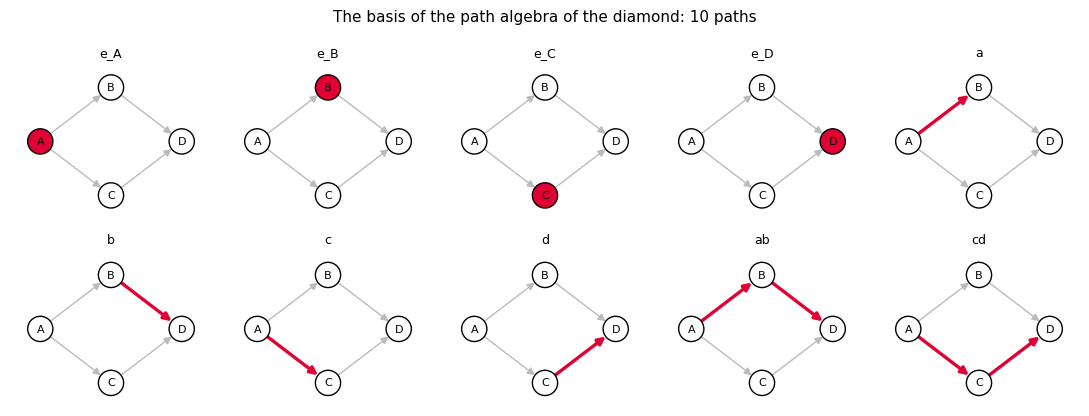

In [ ]:
basis = ([("e_" + v, [], [v]) for v in "ABCD"] + [(x, [x], []) for x in "abcd"]
         + [("ab", ["a", "b"], []), ("cd", ["c", "d"], [])])
fig, axes = plt.subplots(2, 5, figsize=(11, 4.2))
for ax, (name, arrows_, nodes_) in zip(axes.ravel(), basis):
    small_quiver(ax, diamond, pos_d, red_arrows=arrows_, red_nodes=nodes_, title=name)
fig.suptitle("The basis of the path algebra of the diamond: 10 paths", fontsize=11)
plt.tight_layout()
plt.show()

### Paths are counted by powers of the adjacency matrix

The entry $(A^k)_{ij}$ is the number of paths of length $k$ from $i$ to $j$.

In [7]:
A = diamond.adjacency_matrix().astype(int)
print("A =\n", A)
print("\nA^2 =\n", A @ A)
print("\nPaths of length 2 from A to D:", [str(p) for p in kQ.paths_from_to("A", "D", 2)])

A =
 [[0 1 1 0]
 [0 0 0 1]
 [0 0 0 1]
 [0 0 0 0]]

A^2 =
 [[0 0 0 2]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

Paths of length 2 from A to D: ['a · b', 'c · d']


#### Picture: the matrices, with their numbers

Row = where the path starts, column = where it ends. The entry is the number of paths of that length. Look for the 2 in $A^2$: it is the pair `ab`, `cd`. And $A^3$ is all zeros: the diamond has no path of length 3.

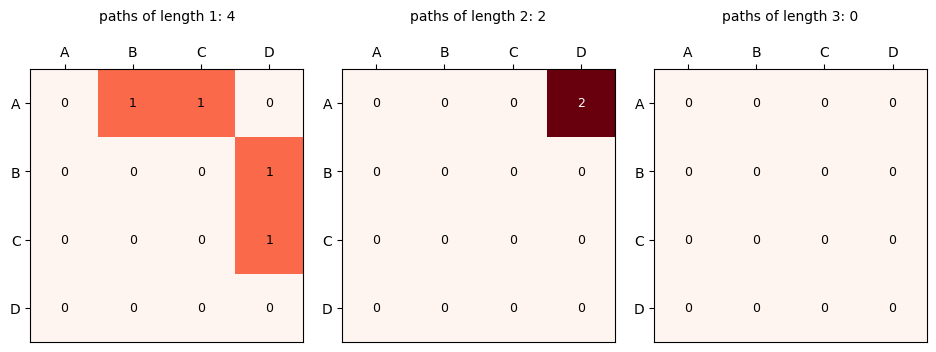

In [ ]:
def show_matrix(ax, M, names, title):
    # A matrix as a coloured grid, with every entry written in its square.
    M = np.asarray(M)
    ax.imshow(M, cmap="Reds", vmin=0, vmax=max(2, M.max()))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > 0.6 * max(2, M.max()) else "black")
    ax.set_xticks(range(len(names)), names)
    ax.set_yticks(range(len(names)), names)
    ax.xaxis.tick_top()
    ax.set_title(title, fontsize=10, pad=18)


fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4))
for ax, k in zip(axes, (1, 2, 3)):
    show_matrix(ax, np.linalg.matrix_power(A, k), list(diamond.Q0),
                f"paths of length {k}: {int(np.linalg.matrix_power(A, k).sum())}")
plt.tight_layout()
plt.show()

#### Try it: your own quiver

Edit the list of arrows and run the cell. Each arrow is `(name, source, target)`. The list below is the diamond plus one arrow `x` from D back to A. **Predict:** what happens to the number of paths of each length when there is a cycle? Then delete `x` and run again.

In [ ]:
my_arrows = [("a", "A", "B"), ("b", "B", "D"), ("c", "A", "C"), ("d", "C", "D"),
             ("x", "D", "A")]          # delete this arrow, or add your own

my_vertices = sorted({v for _, s, t in my_arrows for v in (s, t)})
mine = Quiver(my_vertices, my_arrows)
M_mine = mine.adjacency_matrix().astype(int)
print("number of paths of length 0, 1, 2, ...:",
      [int(np.linalg.matrix_power(M_mine, k).sum()) for k in range(9)])
acyclic = not any(np.linalg.matrix_power(M_mine, len(my_vertices)).ravel())
print("no directed cycles:", acyclic, "→ the path algebra has",
      "finite dimension" if acyclic else "infinite dimension: the counts never reach zero")
draw_quiver(mine, title="Your quiver")

#### Picture: how many paths of each length

Grey bars: the diamond. Red bars: your quiver from the cell above. In the diamond the bars stop at length 2. With the arrow `x` from D back to A they never stop.

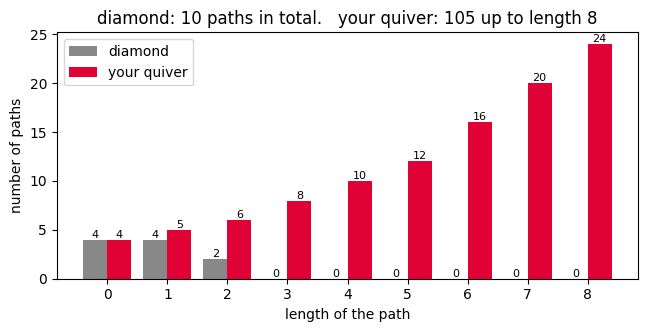

In [ ]:
lengths = range(9)
count_diamond = [int(np.linalg.matrix_power(diamond.adjacency_matrix().astype(int), k).sum()) for k in lengths]
count_mine = [int(np.linalg.matrix_power(M_mine, k).sum()) for k in lengths]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
b1 = ax.bar([k - 0.2 for k in lengths], count_diamond, width=0.4, color="#888888", label="diamond")
b2 = ax.bar([k + 0.2 for k in lengths], count_mine, width=0.4, color="#E00234", label="your quiver")
ax.bar_label(b1, fontsize=8)
ax.bar_label(b2, fontsize=8)
ax.set_xticks(list(lengths))
ax.set_xlabel("length of the path")
ax.set_ylabel("number of paths")
ax.set_title(f"diamond: {sum(count_diamond)} paths in total.   your quiver: {sum(count_mine)} up to length 8")
ax.legend()
plt.show()

### Relations and the quotient KQ / I

A relation can identify two routes, or rule one out. The algebra is $KQ / I$, where the ideal $I$ contains the relations and their consequences. Change one relation at a time.

In [8]:
ab = kQ.path_element(["a", "b"])
cd = kQ.path_element(["c", "d"])

cases = {
    "none":    None,
    "ab = cd": Ideal(kQ, [ab - cd]),
    "ab = 0":  Ideal(kQ, [ab]),
}
rows = []
for name, ideal in cases.items():
    dim = kQ.total_dimension() if ideal is None else QuotientAlgebra(kQ, ideal).total_dimension()
    rows.append({"relation": name, "dim": dim})
pd.DataFrame(rows)

,relation,dim
0,none,10
1,ab = cd,9
2,ab = 0,9


### Removing an arrow or setting a path to zero

*Slide: "Removing an arrow or setting a path to zero".*

Two operations that are easy to confuse. Removing the arrow `b` changes the quiver. Imposing `ab = 0` keeps the four arrows and only forbids that composition. **Predict the two dimensions before you run the cell.**

In [8]:
no_b = Quiver(list("ABCD"), [("a", "A", "B"), ("c", "A", "C"), ("d", "C", "D")])
pd.DataFrame([
    {"what we do": "nothing", "arrows": diamond.n_arrows, "dim": kQ.total_dimension()},
    {"what we do": "remove the arrow b", "arrows": no_b.n_arrows, "dim": PathAlgebra(no_b).total_dimension()},
    {"what we do": "impose ab = 0", "arrows": diamond.n_arrows,
     "dim": QuotientAlgebra(kQ, Ideal(kQ, [ab])).total_dimension()},
])

,what we do,arrows,dim
0,nothing,4,10
1,remove the arrow b,3,8
2,impose ab = 0,4,9


#### Picture: four versions of the diamond

Red marks what each operation touches. Under each title is the list of what happened to the basis.

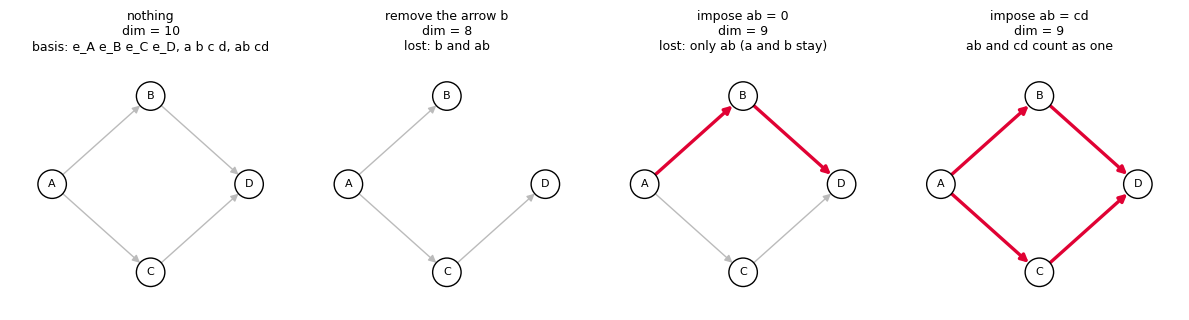

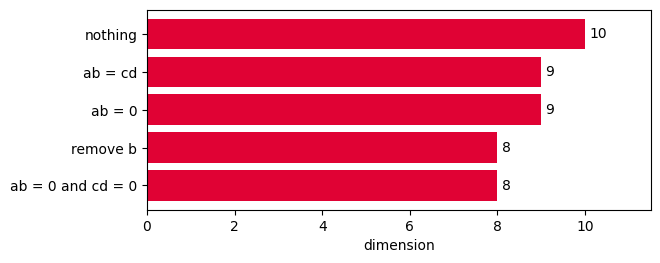

In [ ]:
panels = [
    (diamond, [], "nothing\ndim = 10\nbasis: e_A e_B e_C e_D, a b c d, ab cd"),
    (no_b, [], "remove the arrow b\ndim = 8\nlost: b and ab"),
    (diamond, ["a", "b"], "impose ab = 0\ndim = 9\nlost: only ab (a and b stay)"),
    (diamond, ["a", "b", "c", "d"], "impose ab = cd\ndim = 9\nab and cd count as one"),
]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, (Q, red, title) in zip(axes, panels):
    small_quiver(ax, Q, pos_d, red_arrows=red, title=title, node_size=420)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(["nothing", "ab = cd", "ab = 0", "remove b", "ab = 0 and cd = 0"],
               [10, QuotientAlgebra(kQ, Ideal(kQ, [ab - cd])).total_dimension(),
                QuotientAlgebra(kQ, Ideal(kQ, [ab])).total_dimension(),
                PathAlgebra(no_b).total_dimension(),
                QuotientAlgebra(kQ, Ideal(kQ, [ab, cd])).total_dimension()], color="#E00234")
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, 11.5)
ax.set_xlabel("dimension")
plt.show()

The two answers differ. Without `b` we lose the arrow and the path `ab`: 10 − 2 = 8. With `ab = 0` we lose only the path `ab`: 10 − 1 = 9, and `b` can still be used by any other path that reaches B.

#### Try it: choose the relation

Pick a relation from the list. The quiver never changes; only the rule does. **Predict the dimension before you choose.**

In [ ]:
RELATIONS = {"none": [], "ab = cd": [ab - cd], "ab = 0": [ab], "cd = 0": [cd], "ab = 0 and cd = 0": [ab, cd]}
SURVIVORS = {"none": "ab and cd, as two different things", "ab = cd": "one class, ab = cd", "ab = 0": "cd",
             "cd = 0": "ab", "ab = 0 and cd = 0": "none"}
GONE = {"none": [], "ab = cd": [], "ab = 0": ["ab"], "cd = 0": ["cd"], "ab = 0 and cd = 0": ["ab", "cd"]}
BASIS = ([("e_" + v, [], [v]) for v in "ABCD"] + [(x, [x], []) for x in "abcd"]
         + [("ab", ["a", "b"], []), ("cd", ["c", "d"], [])])


def choose_relation(relation="none"):
    generators = RELATIONS[relation]
    dim = kQ.total_dimension() if not generators else QuotientAlgebra(kQ, Ideal(kQ, generators)).total_dimension()
    fig, axes = plt.subplots(2, 5, figsize=(11, 4.2))
    for ax, (name, arrows_, nodes_) in zip(axes.ravel(), BASIS):
        if name in GONE[relation]:
            small_quiver(ax, diamond, pos_d, title=f"{name} = 0  (gone)")
            ax.plot([0, 1], [0, 1], color="#888888", lw=1.5, transform=ax.transAxes)
            ax.plot([0, 1], [1, 0], color="#888888", lw=1.5, transform=ax.transAxes)
        elif relation == "ab = cd" and name in ("ab", "cd"):
            small_quiver(ax, diamond, pos_d, red_arrows=["a", "b"], blue_arrows=["c", "d"],
                         title="ab = cd  (one element)" if name == "ab" else "(the same element)")
        else:
            small_quiver(ax, diamond, pos_d, red_arrows=arrows_, red_nodes=nodes_, title=name)
    fig.suptitle(f"relation: {relation}      dimension of the algebra: {dim}", fontsize=11)
    plt.tight_layout()
    plt.show()
    print(f"routes from A to D that survive: {SURVIVORS[relation]}")


interact(choose_relation, relation=Dropdown(options=list(RELATIONS), description="relation"));

### A representation

Put a vector space $V_i$ at each vertex and a linear map $f_a : V_i \to V_j$ on each arrow. A path acts by composing the maps, and a relation such as $ab = cd$ becomes the constraint $f_b f_a = f_d f_c$.

In [9]:
rng = np.random.default_rng(0)
f = {name: rng.integers(-2, 3, size=(2, 2)) for name in "abcd"}
print("Random maps satisfy ab = cd?", np.array_equal(f["b"] @ f["a"], f["d"] @ f["c"]))

# One way to satisfy the relation: make the two routes compose to the same map.
f["a"] = np.eye(2, dtype=int)
f["c"] = np.eye(2, dtype=int)
f["d"] = f["b"].copy()
print("After imposing the constraint?", np.array_equal(f["b"] @ f["a"], f["d"] @ f["c"]))

Random maps satisfy ab = cd? False
After imposing the constraint? True


#### Values: the four matrices and the two routes

A representation puts a vector space on every vertex (here $K^2$) and a matrix on every arrow. These are the matrices after imposing the constraint, and the product along each route.

In [ ]:
for name in "abcd":
    print(f"f[{name}] =\n{f[name]}\n")
print("route through B, f[b] · f[a] =\n", f["b"] @ f["a"])
print("\nroute through C, f[d] · f[c] =\n", f["d"] @ f["c"])
v = np.array([1, 2])
print("\nTake the vector", v, "at A. Through B it arrives at D as", f["b"] @ f["a"] @ v,
      "and through C as", f["d"] @ f["c"] @ v)

f[a] =
[[1 0]
 [0 1]]

f[b] =
[[-1 -2]
 [-2 -2]]

f[c] =
[[1 0]
 [0 1]]

f[d] =
[[-1 -2]
 [-2 -2]]

route through B, f[b] · f[a] =
 [[-1 -2]
 [-2 -2]]

route through C, f[d] · f[c] =
 [[-1 -2]
 [-2 -2]]

Take the vector [1 2] at A. Through B it arrives at D as [-5 -6] and through C as [-5 -6]


### A representation with numbers

*Slide: "A representation with numbers".*

The smallest case: every vertex holds one number and every arrow multiplies by a number. A path multiplies the numbers along its route.

In [10]:
def acts(numbers):
    return {"ab": numbers["a"] * numbers["b"], "cd": numbers["c"] * numbers["d"]}


for numbers in ({"a": 2, "b": 3, "c": 1, "d": 6}, {"a": 2, "b": 3, "c": 1, "d": 5}):
    result = acts(numbers)
    print(numbers, "->", result, "| ab = cd holds:", result["ab"] == result["cd"])

{'a': 2, 'b': 3, 'c': 1, 'd': 6} -> {'ab': 6, 'cd': 6} | ab = cd holds: True
{'a': 2, 'b': 3, 'c': 1, 'd': 5} -> {'ab': 6, 'cd': 5} | ab = cd holds: False


#### Picture: the same quiver with numbers on the arrows

Start with the number 1 at A and multiply by each arrow you cross. On the left both routes deliver 6 at D. On the right one route delivers 6 and the other 5: the relation `ab = cd` fails.

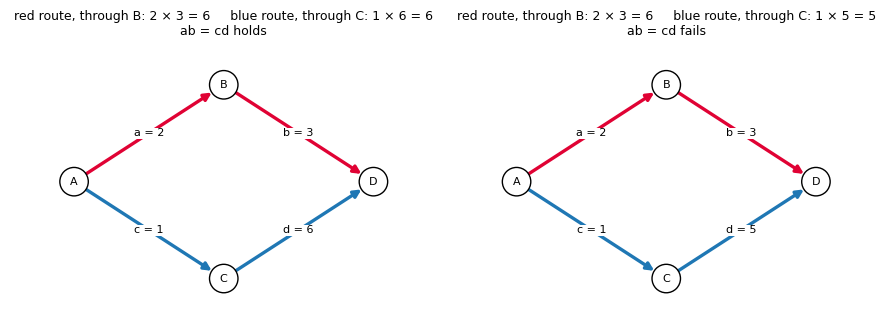

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, numbers in zip(axes, ({"a": 2, "b": 3, "c": 1, "d": 6}, {"a": 2, "b": 3, "c": 1, "d": 5})):
    r = acts(numbers)
    holds = r["ab"] == r["cd"]
    small_quiver(ax, diamond, pos_d, numbers=numbers, node_size=420,
                 red_arrows=["a", "b"], blue_arrows=["c", "d"],
                 title=f"red route, through B: {numbers['a']} × {numbers['b']} = {r['ab']}     "
                       f"blue route, through C: {numbers['c']} × {numbers['d']} = {r['cd']}\n"
                       + ("ab = cd holds" if holds else "ab = cd fails"))
plt.tight_layout()
plt.show()

The second assignment is still a representation of the quiver, but not of the quotient $KQ / I$ with $ab = cd$.

**Exercise (3 minutes).** Find another assignment of four numbers for which $ab = cd$ holds, and check it with `acts`.

#### Try it: four sliders, one relation

Each slider is the number an arrow multiplies by. Move them until the two routes agree. How many different solutions can you find? What do they have in common?

In [ ]:
def try_numbers(a=2, b=3, c=1, d=5):
    numbers = {"a": a, "b": b, "c": c, "d": d}
    result = acts(numbers)
    holds = result["ab"] == result["cd"]
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    small_quiver(ax, diamond, pos_d, numbers=numbers, node_size=520, red_arrows=["a", "b"], blue_arrows=["c", "d"],
                 title=f"red route, through B: {a} × {b} = {result['ab']}       "
                       f"blue route, through C: {c} × {d} = {result['cd']}\n"
                       + ("ab = cd holds: this is a representation of the quotient" if holds
                          else "ab = cd fails: a representation of the quiver, not of the quotient"))
    plt.show()
    print(f"Put 1 at A. It arrives at D as {result['ab']} through B and as {result['cd']} through C.")


interact(try_numbers, a=(-6, 6), b=(-6, 6), c=(-6, 6), d=(-6, 6));

#### Check yourself

In [ ]:
check("paths of length two in the diamond", ...)
check("dimension after removing the arrow b", ...)
check("dimension with ab = cd", ...)

<a id="3"></a>
## 3. Dynamics on a quiver

*Slides: "Impact automata on quivers" to "Exercise: change one choice".*

An impact automaton on a quiver is $\mathcal{A} = (Q, \Sigma, \{A_k\}, \varphi)$: the quiver, the set of states, the neighbourhoods by impact degree, and the update rule. The quiver says where influence can travel, the rule says how.

### A simulated network

Two communities of 15 nodes each, with random arrows inside each community and **one bridge** from the first to the second. The seed is fixed, so everyone gets the same network.

30 vertices, 67 arrows


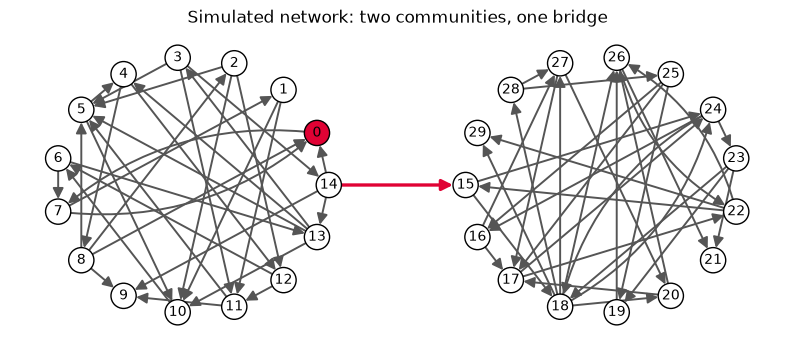

In [10]:
def simulated_network(n_per_community=15, p=0.16, bridge=True, seed=7):
    # Two random directed communities joined by a single bridge arrow.
    rng = np.random.default_rng(seed)
    n = n_per_community
    vertices = list(range(2 * n))
    arrows = []
    for block in (range(0, n), range(n, 2 * n)):
        for i in block:
            for j in block:
                if i != j and rng.random() < p:
                    arrows.append((f"e{i}_{j}", i, j))
    if bridge:
        arrows.append(("bridge", n - 1, n))
    return Quiver(vertices, arrows)


Q_sim = simulated_network()
Q_sim_cut = simulated_network(bridge=False)
print(Q_sim.n_vertices, "vertices,", Q_sim.n_arrows, "arrows")

# Each community on a circle; the bridge endpoints (14 and 15) face each other.
pos_sim = {}
for k in range(15):
    angle = 2 * math.pi * (k + 1) / 15
    pos_sim[k] = (math.cos(angle), math.sin(angle))
    pos_sim[29 - k] = (3.0 - math.cos(angle), math.sin(angle))
draw_quiver(Q_sim, pos_sim, "Simulated network: two communities, one bridge",
            colors={0: "#E00234"}, highlight=["bridge"], labels=False, node_size=330, figsize=(10, 4))

### Run the automaton

States: `S` (susceptible), `I` (active), `R` (removed). The rule is SIR: a susceptible node becomes active with a probability that depends on its active in-neighbours up to distance `g_max` (the rate is scaled by `beta` and clipped to [0, 1]), and an active node is removed with probability `recovery_prob`. Node 0 starts active.

`recovery_prob` is a parameter of this teaching simulator. Do not read it as a calibrated epidemiological rate.

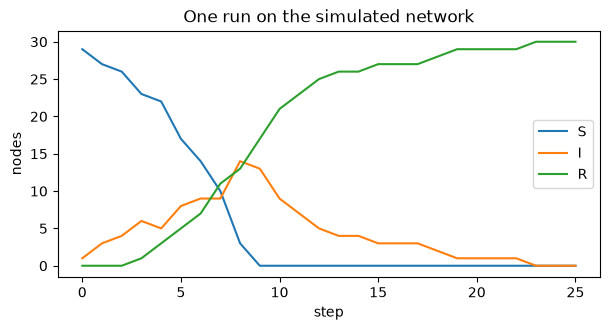

,S,I,R
t,,,
23,0,0,30
24,0,0,30
25,0,0,30


In [11]:
def run_automaton(Q, steps=25, seed=0, beta=3.0, recovery_prob=0.3, g_max=2):
    automaton = AIQ(Q, states=["S", "I", "R"], evolution_rule="SIR",
                    beta=beta, recovery_prob=recovery_prob, g_max=g_max)
    automaton.set_initial_config({v: ("I" if v == 0 else "S") for v in Q.Q0})
    automaton.run(steps, seed=seed)
    return automaton


run = run_automaton(Q_sim)
counts = run.orbit_counts_table().reindex(columns=["S", "I", "R"]).fillna(0).astype(int)
counts.plot(figsize=(7, 3.2), title="One run on the simulated network", xlabel="step", ylabel="nodes")
plt.show()
counts.tail(3)

#### Picture: the same run, seen on the network

The curve above only counts. Here is where it happens. White = susceptible, red = active, grey = removed. The run starts at node 0, in the left community. Look for the step at which the first node of the right community turns red: the signal has crossed the bridge 14 → 15.

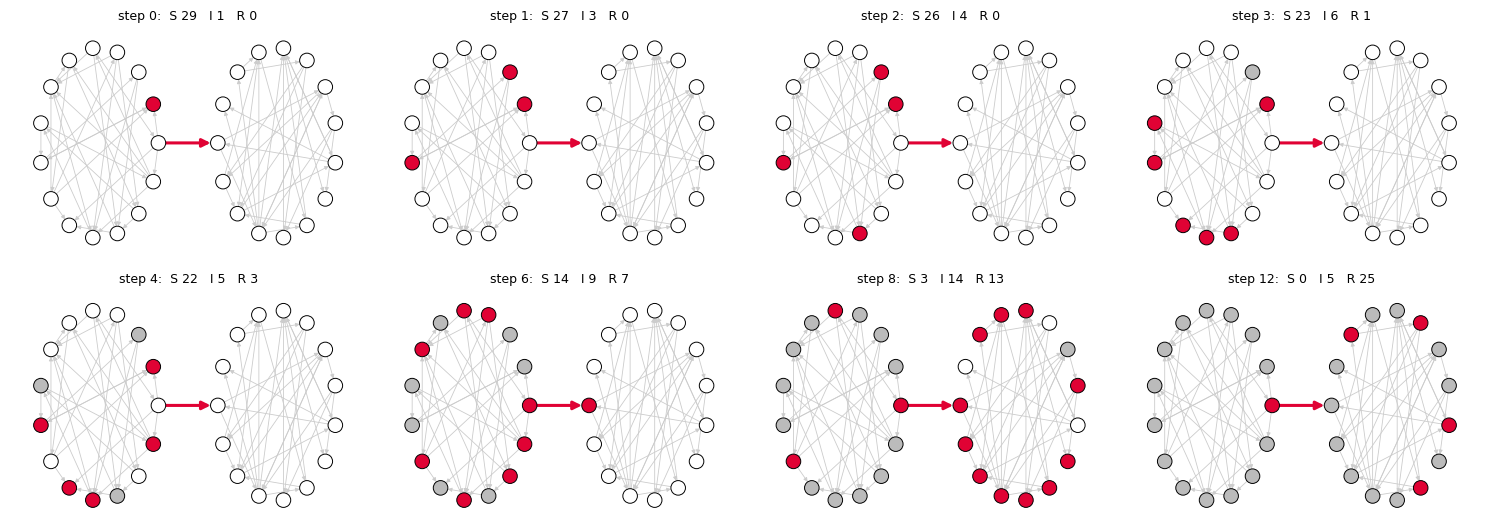

step 1: newly active nodes [1, 7] -> community: left
step 2: newly active nodes [11] -> community: left
step 3: newly active nodes [6, 9, 10] -> community: left
step 4: newly active nodes [13] -> community: left
step 5: newly active nodes [3, 4, 5, 8, 14] -> community: left
step 6: newly active nodes [2, 12, 15] -> community: RIGHT, left
step 7: newly active nodes [16, 23, 24, 27] -> community: RIGHT
step 8: newly active nodes [17, 18, 19, 20, 21, 26, 28] -> community: RIGHT


In [ ]:
STATE_COLORS = {"S": "white", "I": "#E00234", "R": "#BBBBBB"}


def network_state(ax, Q, config, title=""):
    # The simulated network with every node coloured by its state.
    G = nx.DiGraph()
    G.add_nodes_from(Q.Q0)
    G.add_edges_from((s, t) for _, s, t in Q.Q1)
    nx.draw_networkx_edges(G, pos_sim, ax=ax, edge_color="#CCCCCC", width=0.6, arrowsize=6, node_size=110)
    bridge_ = [(s, t) for name, s, t in Q.Q1 if name == "bridge"]
    nx.draw_networkx_edges(G, pos_sim, edgelist=bridge_, ax=ax, edge_color="#E00234", width=2.2,
                           arrowsize=12, node_size=110)
    nx.draw_networkx_nodes(G, pos_sim, nodelist=list(Q.Q0), ax=ax, node_size=110, edgecolors="black",
                           linewidths=0.7, node_color=[STATE_COLORS[config[v]] for v in Q.Q0])
    ax.set_title(title, fontsize=9)
    ax.axis("off")


steps_shown = (0, 1, 2, 3, 4, 6, 8, 12)
fig, axes = plt.subplots(2, 4, figsize=(15, 5.4))
for ax, t in zip(axes.ravel(), steps_shown):
    config = run.orbit[t]
    n = {s: sum(v == s for v in config.values()) for s in "SIR"}
    network_state(ax, Q_sim, config, f"step {t}:  S {n['S']}   I {n['I']}   R {n['R']}")
plt.tight_layout()
plt.show()

for t in range(1, 9):
    new = sorted(v for v in Q_sim.Q0 if run.orbit[t][v] == "I" and run.orbit[t - 1][v] == "S")
    sides = sorted({"left" if v < 15 else "RIGHT" for v in new})
    print(f"step {t}: newly active nodes {new}", "" if not new else f"-> community: {', '.join(sides)}")

#### Try it: watch the automaton on the network

White nodes are susceptible, red nodes are active, grey nodes are removed. Move `step` to advance in time. Change the seed to see another run of the same rule, and switch the bridge off. **Look for:** the step at which the second community receives its first active node.

In [ ]:
STATE_COLORS = {"S": "white", "I": "#E00234", "R": "#BBBBBB"}


def show_automaton(step=0, seed=0, bridge=True):
    Q = Q_sim if bridge else Q_sim_cut
    orbit = run_automaton(Q, seed=seed).orbit
    config = orbit[min(step, len(orbit) - 1)]
    n = {s: sum(v == s for v in config.values()) for s in "SIR"}
    draw_quiver(Q, pos_sim, f"step {step}:   susceptible {n['S']}   active {n['I']}   removed {n['R']}",
                colors={v: STATE_COLORS[s] for v, s in config.items()}, highlight=["bridge"],
                labels=False, node_size=330, figsize=(10, 4))


interact(show_automaton, step=IntSlider(value=0, min=0, max=25, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=20, continuous_update=False),
         bridge=Checkbox(value=True, description="bridge 14 → 15"));

#### Try it: change the rule, keep the network

Now the quiver is fixed and the parameters of the rule move. `beta` scales the impact rate, `recovery_prob` is the probability that an active node is removed, and `g_max` is how many arrows away a node can be influenced from. **Predict:** which parameter can make the signal cross to the second community when the bridge is off?

In [ ]:
def explore_rule(beta=3.0, recovery_prob=0.3, g_max=2, seed=0, bridge=True):
    Q = Q_sim if bridge else Q_sim_cut
    result = run_automaton(Q, seed=seed, beta=beta, recovery_prob=recovery_prob, g_max=g_max)
    counts = result.orbit_counts_table().reindex(columns=["S", "I", "R"]).fillna(0).astype(int)
    counts.plot(figsize=(7, 3.2), xlabel="step", ylabel="nodes", color=["#888888", "#E00234", "#222222"],
                title=f"beta = {beta}, recovery = {recovery_prob}, g_max = {g_max}")
    plt.show()
    print("nodes ever reached:", sum(state != "S" for state in result.config.values()), "of 30")


interact(explore_rule, beta=FloatSlider(value=3.0, min=0.5, max=6.0, step=0.5, continuous_update=False),
         recovery_prob=FloatSlider(value=0.3, min=0.05, max=0.95, step=0.05, continuous_update=False),
         g_max=IntSlider(value=2, min=1, max=4, continuous_update=False),
         seed=IntSlider(value=0, min=0, max=20, continuous_update=False),
         bridge=Checkbox(value=True, description="bridge 14 → 15"));

<details><summary>Answer (open after trying)</summary>

None of them. Without the bridge there is no path from one community to the other, so no value of `beta`, `recovery_prob` or `g_max` can carry the signal across. That is a property of the quiver, and it can be computed before simulating.

</details>

### With and without the bridge

**Predict first:** how many nodes are ever reached with the bridge, and how many without it? One run is not evidence, so we repeat the simulation with 200 different random seeds.

      with bridge  without bridge
mean        27.93           14.13
std          7.13            3.16
min          1.00            1.00
max         30.00           15.00


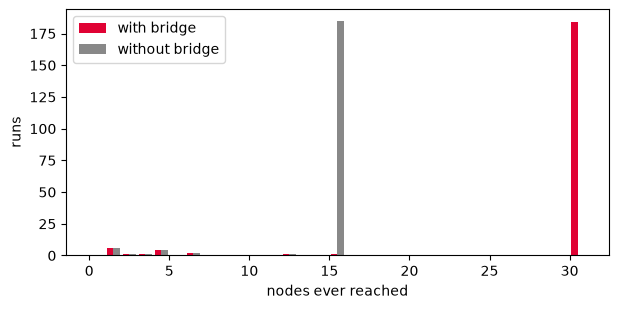

In [12]:
def ever_reached(Q, seed):
    final = run_automaton(Q, seed=seed).config
    return sum(state != "S" for state in final.values())


runs = 200
with_bridge = [ever_reached(Q_sim, s) for s in range(runs)]
without_bridge = [ever_reached(Q_sim_cut, s) for s in range(runs)]
summary = pd.DataFrame({"with bridge": with_bridge, "without bridge": without_bridge})
print(summary.describe().loc[["mean", "std", "min", "max"]].round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([with_bridge, without_bridge], bins=range(0, 32), label=["with bridge", "without bridge"],
        color=["#E00234", "#888888"])
ax.set_xlabel("nodes ever reached")
ax.set_ylabel("runs")
ax.legend()
plt.show()

#### Picture: where the two versions end

The same run (seed 0) on the two networks, at the last step. Grey nodes were reached at some point; white nodes never were. Without the bridge the whole right community stays white, in this run and in every other one.

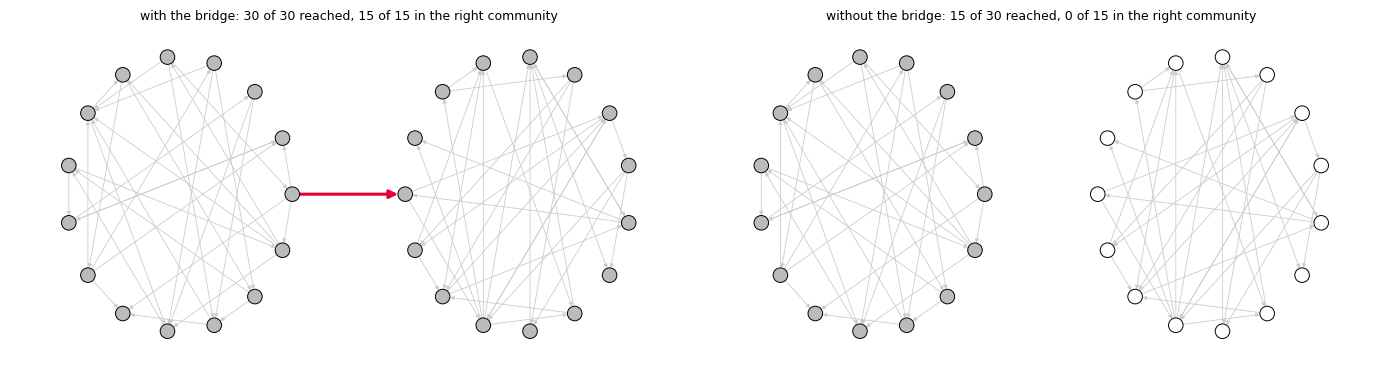

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (Q, label) in zip(axes, ((Q_sim, "with the bridge"), (Q_sim_cut, "without the bridge"))):
    final = run_automaton(Q, seed=0).config
    reached_n = sum(state != "S" for state in final.values())
    right = sum(final[v] != "S" for v in Q.Q0 if v >= 15)
    network_state(ax, Q, final, f"{label}: {reached_n} of 30 reached, {right} of 15 in the right community")
plt.tight_layout()
plt.show()

**How to read this comparison.** The two networks have the same arrows inside each community, the runs use the same seeds, and the rule and its parameters are fixed: only the bridge changes. The comparison is informative inside the simulation. It does not show a causal effect in an observed network, and the axes count steps and nodes, not real cases. Also, one round of the automaton is not one step of the toy of section 1: here impact acts up to degree 2.

### Walk Attention: the support given by walks

Over-squashing: information from many distant nodes has to pass through few routes and is compressed into vectors of fixed size. Walk Attention uses the **support given by walks**: at range $g$, node $j$ may attend to node $i$ when there is a walk of length $g$ from $i$ to $j$, that is, when $(A^g)_{ij} \neq 0$.

Start with the five-node network of the slide and a hop budget.

In [13]:
small = Quiver(list("ABCDE"), [("ab", "A", "B"), ("ac", "A", "C"), ("bd", "B", "D"), ("be", "B", "E"),
                               ("cd", "C", "D"), ("ce", "C", "E"), ("de", "D", "E")])
A = small.adjacency_matrix().astype(int)
names = list(small.Q0)
reached, walks = set(), 0
for g in range(1, 4):
    Ag = np.linalg.matrix_power(A, g)
    row = Ag[names.index("A")]
    reached |= {names[j] for j in np.flatnonzero(row)}
    walks += int(row.sum())
    print(f"hop budget {g}: reach from A = {sorted(reached)},  walks so far = {walks}")

hop budget 1: reach from A = ['B', 'C'],  walks so far = 2
hop budget 2: reach from A = ['B', 'C', 'D', 'E'],  walks so far = 6
hop budget 3: reach from A = ['B', 'C', 'D', 'E'],  walks so far = 8


#### Picture: what A reaches with each hop budget

Red nodes are the ones A can reach with at most g hops. From budget 2 to budget 3 no node is added, but two more walks appear: A → B → D → E and A → C → D → E.

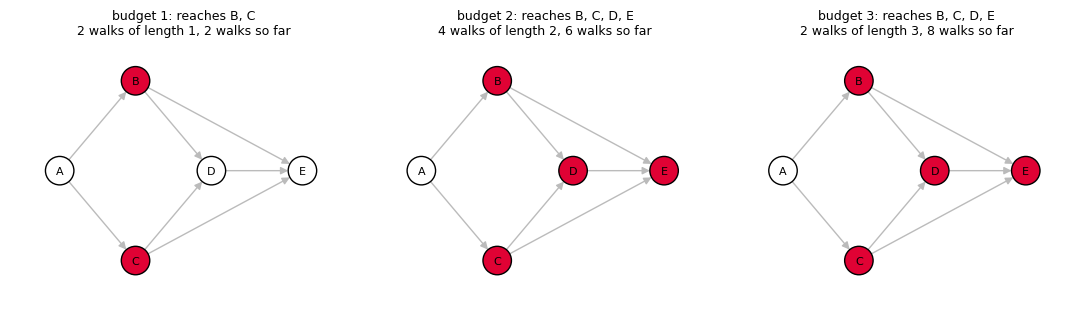

In [ ]:
pos_five = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0), "E": (3.2, 0)}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
reached_, walks_ = set(), 0
for ax, g in zip(axes, (1, 2, 3)):
    row = np.linalg.matrix_power(A, g)[names.index("A")]
    reached_ |= {names[j] for j in np.flatnonzero(row)}
    walks_ += int(row.sum())
    small_quiver(ax, small, pos_five, red_nodes=reached_, node_size=420,
                 title=f"budget {g}: reaches {', '.join(sorted(reached_))}\n"
                       f"{int(row.sum())} walks of length {g}, {walks_} walks so far")
plt.tight_layout()
plt.show()

#### Try it: a hop budget

Choose a source and a number of hops. Pink nodes are reached; the title shows how many walks arrive at each one. Tick `exactly` to count only walks of that exact length. **Compare** "up to 3" with "exactly 3" from A.

In [ ]:
pos_small = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0), "E": (3.2, 0)}


def hop_budget(source="A", hops=1, exactly=False):
    M_small = small.adjacency_matrix().astype(int)
    nodes = list(small.Q0)
    rows = [np.linalg.matrix_power(M_small, k)[nodes.index(source)] for k in range(1, hops + 1)]
    row = rows[-1] if exactly else sum(rows)
    arriving = {nodes[j]: int(row[j]) for j in np.flatnonzero(row)}
    colors = {v: "#F5A3B5" for v in arriving}
    colors[source] = "#E00234"
    draw_quiver(small, pos_small, f"{'exactly' if exactly else 'up to'} {hops} hop(s) from {source} — walks arriving: {arriving}",
                colors=colors, labels=False, figsize=(7, 3.6))


interact(hop_budget, source=Dropdown(options=list("ABCDE"), value="A"), hops=IntSlider(value=1, min=1, max=4),
         exactly=Checkbox(value=False, description="exactly"));

The budget means *up to* g hops. With up to three hops the reached nodes are the same as with up to two, but more walks contribute. With *exactly* three hops from A we only arrive at E. Reach and number of walks are different quantities.

Now the same question on the simulated network: how many ordered pairs can exchange information at each range? This is the support that a path-based attention would use, compared with the full square that standard attention fills.

In [14]:
def support_table(Q, max_range=6):
    A = Q.adjacency_matrix().astype(float)
    n = Q.n_vertices
    rows, Ag = [], np.eye(n)
    for g in range(1, max_range + 1):
        Ag = Ag @ A
        pairs = int((Ag > 0).sum())
        rows.append({"range g": g, "pairs with a walk": pairs,
                     "% of all pairs": round(100 * pairs / n**2, 1),
                     "largest walk count": int(Ag.max())})
    return pd.DataFrame(rows).set_index("range g")


support_table(Q_sim)

,pairs with a walk,% of all pairs,largest walk count
range g,,,
1,67,7.4,1
2,132,14.7,2
3,226,25.1,4
4,331,36.8,8
5,402,44.7,14
6,450,50.0,36


### Exact length, and with or without the bridge

*Slides: "What the powers of the adjacency matrix count" and "Exact length and reach in the simulated network".*

The entry $(A^g)_{uv}$ counts the walks of length **exactly** $g$ from $u$ to $v$ (rows are sources, columns are targets). The support $S_g$ is the set of pairs where that entry is not zero. Support, multiplicity and learned weight are three different objects. First the toy network of section 1, then the simulated one.

In [16]:
A_toy = Q_toy.adjacency_matrix().astype(int)
A_cut = Q_cut.adjacency_matrix().astype(int)
ix = {v: i for i, v in enumerate(Q_toy.Q0)}
for g, target in ((2, "D"), (3, "E"), (4, "F")):
    n_with = np.linalg.matrix_power(A_toy, g)[ix["A"], ix[target]]
    n_without = np.linalg.matrix_power(A_cut, g)[ix["A"], ix[target]]
    print(f"walks of length {g} from A to {target}: {n_with} with the bridge, {n_without} without it")

walks of length 2 from A to D: 2 with the bridge, 2 without it
walks of length 3 from A to E: 2 with the bridge, 0 without it
walks of length 4 from A to F: 2 with the bridge, 0 without it


#### Picture: the same counts as matrices

Top row with the bridge, bottom row without it. Read the row of A. In the top row a 2 appears under D, then under E, then under F. In the bottom row the columns of E and F stay at zero for every length.

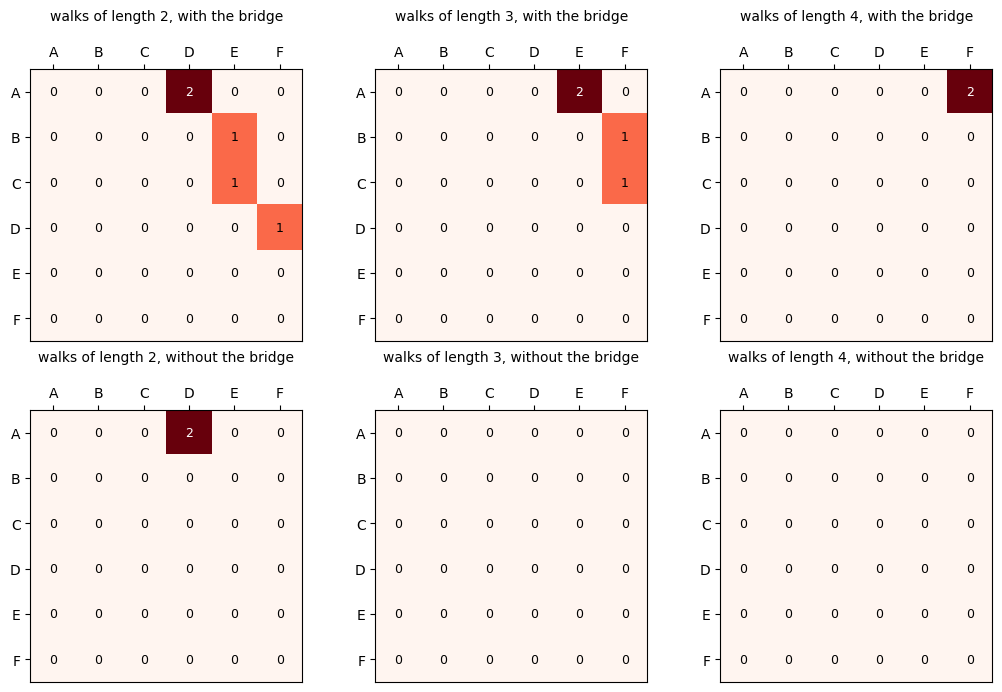

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 7))
for row_axes, (M, label) in zip(axes, ((A_toy, "with the bridge"), (A_cut, "without the bridge"))):
    for ax, g in zip(row_axes, (2, 3, 4)):
        show_matrix(ax, np.linalg.matrix_power(M, g), list(Q_toy.Q0), f"walks of length {g}, {label}")
plt.tight_layout()
plt.show()

In [17]:
with_b, without_b = support_table(Q_sim), support_table(Q_sim_cut)
pd.DataFrame({"pairs, no bridge": without_b["pairs with a walk"],
              "pairs, with bridge": with_b["pairs with a walk"],
              "% of all pairs, with bridge": with_b["% of all pairs"],
              "largest walk count, with bridge": with_b["largest walk count"]})

,"pairs, no bridge","pairs, with bridge","% of all pairs, with bridge","largest walk count, with bridge"
range g,,,,
1,66,67,7.4,1
2,129,132,14.7,2
3,214,226,25.1,4
4,304,331,36.8,8
5,359,402,44.7,14
6,388,450,50.0,36


#### Picture: the table as two curves

Left: how many of the 900 ordered pairs are joined by a walk of exactly g steps. The two curves separate as g grows; the gap is the pairs that only exist through the bridge. Right: the largest number of walks between one pair.

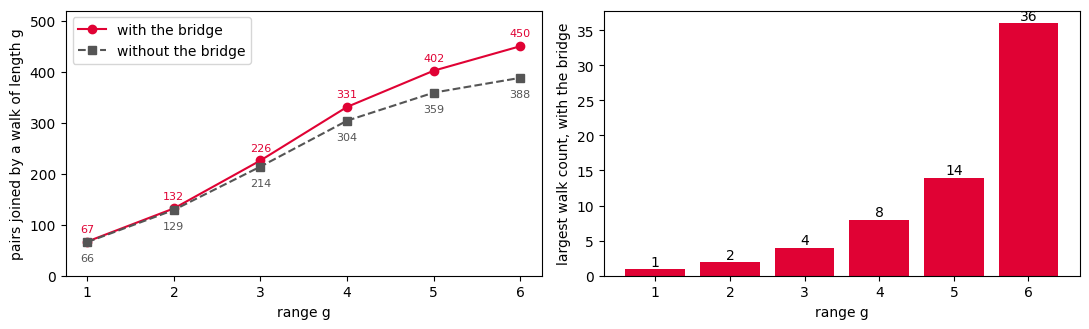

pairs that exist only thanks to the bridge, g = 1..6: [1, 3, 12, 27, 43, 62]


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
ax1.plot(with_b.index, with_b["pairs with a walk"], "o-", color="#E00234", label="with the bridge")
ax1.plot(without_b.index, without_b["pairs with a walk"], "s--", color="#555555", label="without the bridge")
for g in with_b.index:
    ax1.annotate(int(with_b.loc[g, "pairs with a walk"]), (g, with_b.loc[g, "pairs with a walk"]),
                 textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color="#E00234")
    ax1.annotate(int(without_b.loc[g, "pairs with a walk"]), (g, without_b.loc[g, "pairs with a walk"]),
                 textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#555555")
ax1.set_xlabel("range g")
ax1.set_ylabel("pairs joined by a walk of length g")
ax1.set_ylim(0, 520)
ax1.legend()
bars = ax2.bar(with_b.index, with_b["largest walk count"], color="#E00234")
ax2.bar_label(bars)
ax2.set_xlabel("range g")
ax2.set_ylabel("largest walk count, with the bridge")
plt.tight_layout()
plt.show()
gap = with_b["pairs with a walk"] - without_b["pairs with a walk"]
print("pairs that exist only thanks to the bridge, g = 1..6:", list(gap))

One arrow changed, and at range 6 the two networks differ by 62 pairs. The largest walk count keeps growing even where the set of reachable nodes does not. Identifying two walks in a quotient would lower the number of classes between two nodes, but it would not remove the connection between them.

#### Try it: see the support

Each red cell is an ordered pair (source, target) joined by a walk. Nodes 0 to 14 are the first community and 15 to 29 the second. Move `g`, switch the bridge off, and tick `up to` to take the union of the ranges. **Look for:** the block that stays empty for ever, and the block that the bridge fills.

In [ ]:
def show_support(g=1, bridge=True, up_to=False):
    Q = Q_sim if bridge else Q_sim_cut
    M_sim = Q.adjacency_matrix().astype(float)
    layers = [np.linalg.matrix_power(M_sim, k) > 0 for k in range(1, g + 1)]
    support = np.any(layers, axis=0) if up_to else layers[-1]
    fig, ax = plt.subplots(figsize=(4.4, 4.4))
    ax.imshow(support, cmap="Reds", vmin=0, vmax=1)
    ax.axhline(14.5, color="#888888", lw=0.8)
    ax.axvline(14.5, color="#888888", lw=0.8)
    ax.set_xlabel("target")
    ax.set_ylabel("source")
    ax.set_title(f"{'up to' if up_to else 'exactly'} {g} hop(s): {int(support.sum())} of 900 pairs")
    plt.show()


interact(show_support, g=IntSlider(value=1, min=1, max=8), bridge=Checkbox(value=True, description="bridge 14 → 15"),
         up_to=Checkbox(value=False, description="up to"));

#### Check yourself

In [ ]:
check("node reached from A with exactly three hops", ...)      # a letter, in quotes
check("pairs gained at range 6 thanks to the bridge", ...)

### A bottleneck

$K$ sources feed $d$ layers of $M$ nodes, and everything ends in one target. The number of walks that arrive at the target grows like $K \cdot M^{d}$, while the target keeps a vector of fixed size.

In [15]:
def bottleneck(K=4, M=3, depth=2):
    layers = [[f"s{i}" for i in range(K)]]
    layers += [[f"h{l}_{i}" for i in range(M)] for l in range(depth)]
    layers += [["target"]]
    arrows = [(f"{u}>{v}", u, v) for a, b in zip(layers, layers[1:]) for u in a for v in b]
    return Quiver([v for layer in layers for v in layer], arrows)


for depth in (1, 2, 3, 4):
    Qb = bottleneck(depth=depth)
    Ab = Qb.adjacency_matrix().astype(int)
    arriving = int(np.linalg.matrix_power(Ab, depth + 1)[:, list(Qb.Q0).index("target")].sum())
    print(f"depth {depth}: {arriving:4d} walks arrive at the target   (K·M^d = {4 * 3**depth})")

depth 1:   12 walks arrive at the target   (K·M^d = 12)
depth 2:   36 walks arrive at the target   (K·M^d = 36)
depth 3:  108 walks arrive at the target   (K·M^d = 108)
depth 4:  324 walks arrive at the target   (K·M^d = 324)


#### Picture: the bottleneck network

Four sources on the left, one target on the right, and two layers of three nodes in between. Every walk from a source to the target is one choice per layer: 4 × 3 × 3 = 36 walks arrive at the same node, and only one of them carries the information the task asks for.

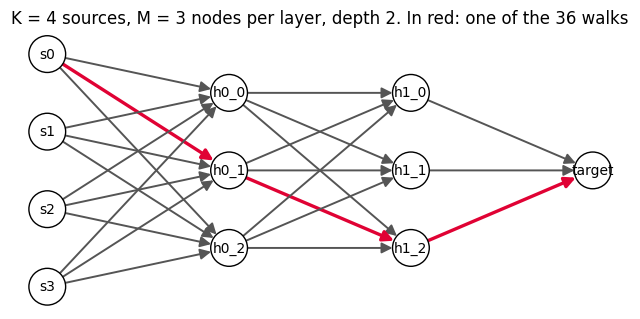

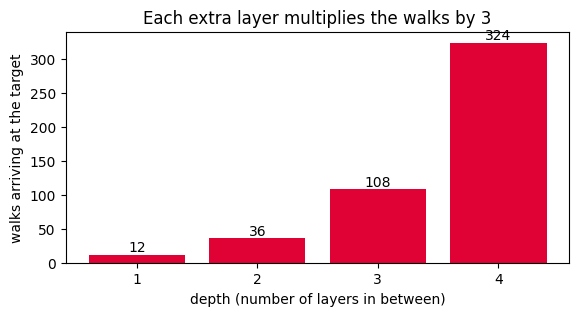

In [ ]:
Qb = bottleneck(K=4, M=3, depth=2)
layers_ = [[v for v in Qb.Q0 if v.startswith("s")], [v for v in Qb.Q0 if v.startswith("h0")],
           [v for v in Qb.Q0 if v.startswith("h1")], ["target"]]
pos_b = {v: (x, (len(layer) - 1) / 2 - i) for x, layer in enumerate(layers_) for i, v in enumerate(layer)}
one_walk = ["s0>h0_1", "h0_1>h1_2", "h1_2>target"]
draw_quiver(Qb, pos_b, "K = 4 sources, M = 3 nodes per layer, depth 2. In red: one of the 36 walks",
            highlight=one_walk, labels=False, node_size=700, figsize=(8, 3.6))

depths = (1, 2, 3, 4)
fig, ax = plt.subplots(figsize=(6.5, 3))
bars = ax.bar([str(d) for d in depths], [4 * 3**d for d in depths], color="#E00234")
ax.bar_label(bars)
ax.set_xlabel("depth (number of layers in between)")
ax.set_ylabel("walks arriving at the target")
ax.set_title("Each extra layer multiplies the walks by 3")
plt.show()

### Exercise: change one choice

Keep the network and the measurement fixed. Change **one** structural choice, for example:

- the hop budget `max_range` in `support_table`,
- the bridge (`Q_sim` against `Q_sim_cut`),
- the density `p` in `simulated_network`,
- `g_max` or `recovery_prob` in `run_automaton`.

Write a four-line experiment log:

1. Our hypothesis
2. The single change we made
3. What we observed
4. What we still cannot conclude

In [16]:
# Your experiment. Example: the support without the bridge.
support_table(Q_sim_cut)

,pairs with a walk,% of all pairs,largest walk count
range g,,,
1,66,7.3,1
2,129,14.3,2
3,214,23.8,4
4,304,33.8,8
5,359,39.9,14
6,388,43.1,36


<a id="4"></a>
## 4. Brauer configurations

*Slides: "Configuration, quiver, relations, algebra" to "Simulated corpora".*

### Why we need another object

Three articles cite the same reference $c$. If we join two articles whenever they share a citation, we draw a triangle. We would draw the same triangle if each pair of articles shared a different reference and no reference was cited by all three. The triangle says that every pair overlaps; it cannot say whether the three overlaps come from one reference or from three. To ask that question we have to keep the reference lists.

A graph records pairs. A reference list with ten items is a group of ten: turned into pairs it becomes 45 edges, and the fact that the ten were together is lost. The first picture below shows the two cases.

### What a Brauer configuration keeps

A Brauer configuration (Green and Schroll, 2017) is four pieces of data, $\Gamma = (\Gamma_0, \Gamma_1, \mu, \mathcal{O})$:

| Datum | What it is | In the example of the articles |
|---|---|---|
| $\Gamma_0$, the vertices | the things that can be shared | the references |
| $\Gamma_1$, the polygons | groups of vertices; a polygon has at least two | the articles: each article is the group of its references |
| $\mu$, the multiplicity | a positive whole number for each vertex. It is a choice of the model, not a count | how many turns around a reference are allowed before stopping |
| $\mathcal{O}$, the orientation | for each vertex, the polygons that contain it, written in a circle. Also a choice | the articles that cite a reference, from the oldest to the newest |

Two words used all the time:

- **Valency**, $\mathrm{val}(x)$: the number of times the vertex $x$ occurs in the polygons. For a reference: how many times the corpus cites it.
- **Truncated vertex**: a vertex with $\mu(x)\,\mathrm{val}(x) = 1$, that is, it occurs once and its multiplicity is one. A truncated vertex draws no arrow.

### Three levels: configuration → quiver → algebra

Keep the three levels apart. Each one is built from the previous one.

**1. From the configuration to the quiver.** The nodes of the quiver are the *polygons*, not the vertices. For each vertex $x$, write the polygons that contain it in the chosen order, $V_1, V_2, \dots, V_k$, and draw an arrow from each one to the next, and one more from the last back to the first. So every vertex draws its own cycle, with $\mathrm{val}(x)$ arrows. A vertex that lies in a single polygon and has $\mu > 1$ draws a loop.

**2. From the quiver to the relations.** Three rules decide which paths are equal and which are zero:

- *Identify.* Inside one polygon, a complete turn around one vertex equals a complete turn around any other vertex of that polygon ("complete" means $\mu$ turns of the cycle).
- *Stop.* A complete turn cannot be continued: adding one more arrow gives zero.
- *Do not mix.* A path that starts in the cycle of one vertex and jumps to the cycle of another is zero.

**3. The algebra.** $\Lambda = KQ/I$: the paths of the quiver, with those three rules imposed. The quiver has cycles, so its path algebra alone would have infinite dimension (remember the arrow `x` in section 2). The rules cut it down to a finite one.

### The numbers of the tables, in words

| Column | What it counts | How to read it |
|---|---|---|
| `arrows` | $\sum \mathrm{val}(x)$ over the vertices that are not truncated | one arrow per occurrence of a vertex |
| `loops` | vertices that lie in one polygon only (with $\mu > 1$) | references cited by a single article |
| `δ` | the total mass, $\sum \mu(x)\,\mathrm{val}(x)$ | a size. It is not quality or influence |
| `H (bits)` | the entropy of the shares $p_x = \mu(x)\,\mathrm{val}(x)/\delta$, $H = -\sum p_x \log_2 p_x$ | how evenly the mass is spread over the vertices |
| `log2 \|Γ0\|` | the largest value $H$ can take with that many vertices | reached only when all the masses are equal |
| `dim Λ` | $2\,\lvert\Gamma_1\rvert + \sum_x \mathrm{val}(x)\,(\mu(x)\,\mathrm{val}(x) - 1)$ | how many different paths survive the three rules |
| `dim Z(Λ)` | the dimension of the centre | how many independent elements commute with everything |

The formula for $\dim \Lambda$ can be read term by term. The first term counts, for every polygon, its trivial path and one "complete turn". The second counts, for each of the $\mathrm{val}(x)$ occurrences of a vertex, the $\mu(x)\,\mathrm{val}(x) - 1$ unfinished pieces of a turn that start there.

The function `explain` defined below prints these numbers vertex by vertex, so that no total appears without its terms.

In [17]:
def report(bc, name=""):
    # The quantities used in the slides, for one Brauer configuration.
    r = bc.brauer_analysis()
    n = r["n_vertices"]
    return {"configuration": name, "polygons": r["n_polygons"], "vertices": n,
            "arrows": bc.brauer_quiver().n_arrows, "loops": r["n_loops"],
            "dim Λ": r["dimension"], "dim Z(Λ)": r["center_dimension"],
            "δ": int(r["impact_factor_delta_B"]), "H (bits)": round(r["entropy_H_B"], 4),
            "log2 |Γ0|": round(math.log2(n), 4)}


def successors(bc):
    for v, seq in bc.successor_sequences().items():
        polygons = [p for p, _ in seq]
        print(f"  {v}: val = {bc.valency(v)}, μ = {bc.mu(v)}, cycle "
              + " → ".join(map(str, polygons + polygons[:1])))

#### Picture: two different corpora, the same triangle

Left: one reference, $c$, is cited by the three articles. Middle: three references, each one shared by one pair of articles. Right: what a graph of pairs keeps in both cases. Squares are articles, circles are references.

The cell also defines `explain`, which opens up the numbers of a configuration vertex by vertex.

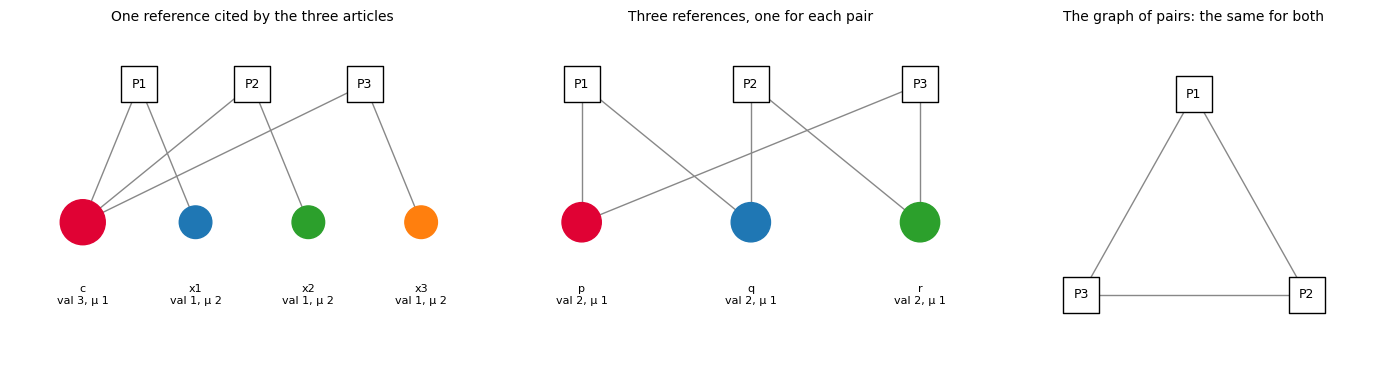

In [ ]:
VERTEX_COLORS = ["#E00234", "#1F77B4", "#2CA02C", "#FF7F0E", "#9467BD", "#8C564B"]


def draw_configuration(bc, polygons, ax, title=""):
    # Polygons above (squares), vertices below (circles). The label of a vertex shows val and μ.
    P, V = list(polygons), list(bc.Gamma0)
    pos = {p: (i - (len(P) - 1) / 2, 1) for i, p in enumerate(P)}
    pos.update({v: ((i - (len(V) - 1) / 2) * max(1, len(P) / len(V)), 0) for i, v in enumerate(V)})
    G = nx.Graph()
    G.add_edges_from((p, v) for p in P for v in polygons[p])
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#888888")
    nx.draw_networkx_nodes(G, pos, nodelist=P, node_shape="s", node_color="white", edgecolors="black",
                           node_size=700, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=V, node_color=[VERTEX_COLORS[i % 6] for i in range(len(V))],
                           node_size=[300 + 250 * bc.valency(v) for v in V], ax=ax)
    nx.draw_networkx_labels(G, pos, labels={p: p for p in P}, font_size=9, ax=ax)
    for v in V:
        ax.text(pos[v][0], -0.45, f"{v}\nval {bc.valency(v)}, μ {bc.mu(v)}", ha="center", va="top", fontsize=8)
    ax.set_ylim(-1.0, 1.4)
    ax.margins(x=0.15)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def draw_brauer_quiver(bc, pos, ax, title=""):
    # The Brauer quiver, with the arrows of each vertex in the colour of that vertex.
    Q, V = bc.brauer_quiver(), list(bc.Gamma0)
    G = nx.MultiDiGraph()
    G.add_nodes_from(Q.Q0)
    nx.draw_networkx_nodes(G, pos, nodelist=list(Q.Q0), node_shape="s", node_color="white",
                           edgecolors="black", node_size=700, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
    seen = {}
    for name, s, t in Q.Q1:
        vertex = next(v for v in sorted(V, key=len, reverse=True) if name.startswith(f"s_{v}_"))
        k = seen.get((s, t), 0)
        seen[(s, t)] = k + 1
        nx.draw_networkx_edges(nx.DiGraph([(s, t)]), pos, ax=ax, node_size=700, arrowsize=14, width=1.8,
                               edge_color=VERTEX_COLORS[V.index(vertex) % 6],
                               connectionstyle=f"arc3,rad={0.18 + 0.22 * k}")
    for i, v in enumerate(V):
        ax.plot([], [], color=VERTEX_COLORS[i % 6], lw=2, label=f"cycle of {v}")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=min(len(V), 5), frameon=False)
    ax.margins(0.25)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def explain(bc, polygons):
    # The numbers of a configuration, one row per vertex, and how the totals are obtained from the rows.
    rows = []
    for v in bc.Gamma0:
        val, mu = bc.valency(v), bc.mu(v)
        rows.append({"vertex": v, "lies in": ", ".join(p for p in polygons if v in polygons[p]),
                     "val": val, "μ": mu, "mass = μ·val": mu * val,
                     "arrows it draws": val if mu * val > 1 else 0,
                     "adds to dim Λ: val·(μ·val − 1)": val * (mu * val - 1)})
    t = pd.DataFrame(rows).set_index("vertex")
    total = int(t["mass = μ·val"].sum())
    t["share of the mass"] = (t["mass = μ·val"] / total).round(3)
    display(t)
    extra = int(t["adds to dim Λ: val·(μ·val − 1)"].sum())
    H_ = -sum(m_ / total * math.log2(m_ / total) for m_ in t["mass = μ·val"])
    print(f"arrows of the quiver = sum of 'arrows it draws' = {int(t['arrows it draws'].sum())}")
    print(f"δ = sum of the masses = {total}")
    print(f"dim Λ = 2 × {len(polygons)} polygons + {extra} = {2 * len(polygons) + extra}")
    print(f"H = {H_:.4f} bits. With {len(t)} vertices the maximum is log2({len(t)}) = {math.log2(len(t)):.4f}, "
          "reached only if all the masses are equal")


one_shared = {"P1": ["c", "x1"], "P2": ["c", "x2"], "P3": ["c", "x3"]}
three_shared = {"P1": ["p", "q"], "P2": ["q", "r"], "P3": ["p", "r"]}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for ax, polygons_, title in ((axes[0], one_shared, "One reference cited by the three articles"),
                             (axes[1], three_shared, "Three references, one for each pair")):
    vertices_ = sorted({v for refs in polygons_.values() for v in refs})
    draw_configuration(BrauerConfiguration(vertices=vertices_, polygons=polygons_), polygons_, ax, title)
triangle = nx.Graph([("P1", "P2"), ("P2", "P3"), ("P1", "P3")])
nx.draw_networkx(triangle, {"P1": (0, 1), "P2": (1, -0.6), "P3": (-1, -0.6)}, ax=axes[2], node_shape="s",
                 node_color="white", edgecolors="black", node_size=700, font_size=9, edge_color="#888888")
axes[2].set_title("The graph of pairs: the same for both", fontsize=10)
axes[2].margins(0.25)
axes[2].axis("off")
plt.tight_layout()
plt.show()

### 4.1 Two polygons, two shared vertices

The smallest example with something to see. Two polygons, $P$ and $Q$, with the same content $\{\alpha, \beta\}$ and $\mu = 1$. Think of two articles with the same two references.

**The quiver.** The vertex $\alpha$ lies in $P$ and in $Q$, so it draws the cycle $P \to Q \to P$: an arrow $a : P \to Q$ and an arrow $b : Q \to P$. The vertex $\beta$ does the same with two other arrows, $c : P \to Q$ and $d : Q \to P$. Four arrows in total, two nodes.

**The relations.** There are eight paths of length two. This is what the three rules do to each one:

| Path | What it does | Rule | Result |
|---|---|---|---|
| $ab$ | a complete turn around $\alpha$, from $P$ to $P$ | identify | $ab = cd$ |
| $cd$ | a complete turn around $\beta$, from $P$ to $P$ | identify | the same element as $ab$ |
| $ba$ | a complete turn around $\alpha$, from $Q$ to $Q$ | identify | $ba = dc$ |
| $dc$ | a complete turn around $\beta$, from $Q$ to $Q$ | identify | the same element as $ba$ |
| $ad$, $cb$ | start with one vertex, come back with the other | do not mix | $0$ |
| $bc$, $da$ | the same, starting at $Q$ | do not mix | $0$ |

Every path of length three is zero: $aba = 0$ because a complete turn cannot be continued, and $abc = a(bc) = 0$ because $bc$ mixes two cycles.

**The basis.** What survives is $\{e_P,\ e_Q,\ a,\ b,\ c,\ d,\ ab,\ ba\}$: eight elements. The formula agrees: $2 \cdot 2 + 2\,(2 - 1) + 2\,(2 - 1) = 8$.

Compare with the diamond of section 2. There, $ab = cd$ identified two routes with the same endpoints. Here the equality is placed between two complete turns at the same polygon, and the routes that change vertex half-way are set to zero.

In [18]:
two = BrauerConfiguration(vertices=["alpha", "beta"],
                          polygons={"P": ["alpha", "beta"], "Q": ["alpha", "beta"]})
successors(two)
pd.DataFrame([report(two, "two polygons")])

  alpha: val = 2, μ = 1, cycle P → Q → P
  beta: val = 2, μ = 1, cycle P → Q → P


,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,two polygons,2,2,4,0,8,3,4,1.0,1.0


#### Picture: the configuration and its quiver

Left: the configuration. Squares are polygons, circles are vertices, and a line means "this polygon contains this vertex". Right: the Brauer quiver. Its nodes are the polygons, and each vertex of the configuration draws its own cycle of arrows, in its own colour.

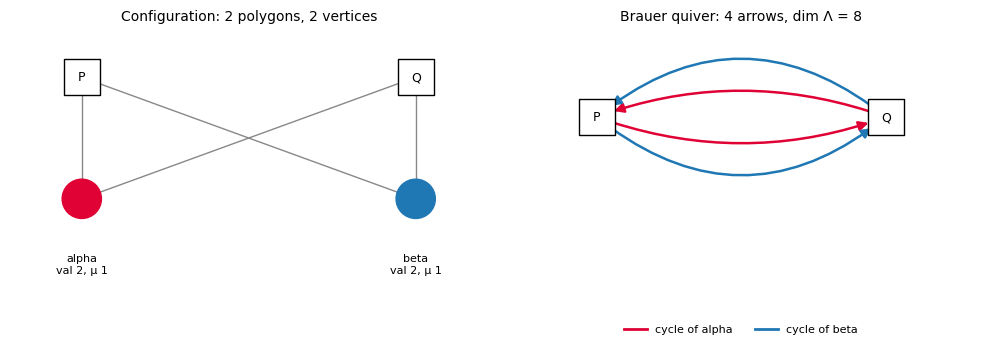

,lies in,val,μ,mass = μ·val,arrows it draws,adds to dim Λ: val·(μ·val − 1),share of the mass
vertex,,,,,,,
alpha,"P, Q",2,1,2,2,2,0.5
beta,"P, Q",2,1,2,2,2,0.5


arrows of the quiver = sum of 'arrows it draws' = 4
δ = sum of the masses = 4
dim Λ = 2 × 2 polygons + 4 = 8
H = 1.0000 bits. With 2 vertices the maximum is log2(2) = 1.0000, reached only if all the masses are equal


In [ ]:
two_polygons = {"P": ["alpha", "beta"], "Q": ["alpha", "beta"]}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
draw_configuration(two, two_polygons, ax1, "Configuration: 2 polygons, 2 vertices")
draw_brauer_quiver(two, {"P": (0, 0), "Q": (2, 0)}, ax2, "Brauer quiver: 4 arrows, dim Λ = 8")
plt.tight_layout()
plt.show()
explain(two, two_polygons)

### The centre, by hand

*Slide: "The centre of the two-polygon algebra, by hand".*

The centre is $Z(\Lambda) = \{ z : zu = uz \text{ for every } u \}$. It does not count paths one by one: it collects the combinations that commute with the whole algebra. In this example it can be found without a formula. Write a candidate $z$ in the basis of eight elements and ask what commuting forces.

1. **Commute with $e_P$ and $e_Q$.** Every arrow joins $P$ and $Q$, so $e_P\,a = a$ but $a\,e_P = 0$. If $z$ contained the arrow $a$, the two products would differ. No arrow can appear in $z$.
2. **Commute with the arrows.** If $z = x\,e_P + y\,e_Q + \dots$, then $za = x\,a$ and $az = y\,a$, so $x = y$. The two trivial paths can only appear together, as $e_P + e_Q$ (the unit of the algebra).
3. **The complete turns.** The classes $ab$ and $ba$ are central: their product with any arrow is zero on both sides.

A basis of the centre is $\{e_P + e_Q,\ ab,\ ba\}$: dimension 3, the value in the column `dim Z(Λ)` above. The formula of Sierra gives the same: $1 + 2 + 2 - 2 + 0 - 0 = 3$.

### 4.2 The published example with four polygons

Source: Moreno Cañadas et al., *Electron. Res. Arch.* 32(10), 2024.

$$M_1 = \{m_1, m_2\}, \qquad M_2 = \{m_2, m_3\}, \qquad M_3 = \{m_3, m_4\}, \qquad M_4 = \{m_2, m_4\}, \qquad \mu = (2, 1, 1, 1)$$

**Step 1, valencies and masses.** Count in how many polygons each vertex lies: $m_1$ in one, $m_2$ in three, $m_3$ in two, $m_4$ in two. The masses $\mu \cdot \mathrm{val}$ are $2, 3, 2, 2$. None equals 1, so no vertex is truncated.

**Step 2, the cycles.** Each vertex draws its cycle among the polygons that contain it:

| Vertex | Its cycle | Arrows |
|---|---|---|
| $m_1$ | $M_1 \to M_1$ | a loop, $\ell$ |
| $m_2$ | $M_1 \to M_2 \to M_4 \to M_1$ | $a, b, c$ |
| $m_3$ | $M_2 \to M_3 \to M_2$ | $d, e$ |
| $m_4$ | $M_3 \to M_4 \to M_3$ | $f, g$ |

That is $1 + 3 + 2 + 2 = 8$ arrows and one loop. The loop does not mean that $m_1$ is truncated: its mass is 2, because $\mu(m_1) = 2$.

**Step 3, the relations.**

- *Identify*, one equality per polygon: $\ell^2 = abc$ at $M_1$, $bca = de$ at $M_2$, $ed = fg$ at $M_3$, $cab = gf$ at $M_4$. At $M_1$ you can see what the multiplicity 2 does: two passes through the loop count as one complete turn around $m_2$.
- *Stop*: for instance $\ell^3 = 0$ and $abca = 0$.
- *Do not mix*: for instance $ad = 0$. The arrow $a$ ends at $M_2$ and $d$ starts at $M_2$, so the path exists in the quiver, but it changes from the cycle of $m_2$ to the cycle of $m_3$.

**Exercise.** Before running the cell, compute by hand the number of arrows, $\delta$ and $\dim \Lambda$ with the formula. Then check the published values $\dim \Lambda = 19$, $\dim Z(\Lambda) = 6$ and $H = 1.9749$.

In [19]:
published = BrauerConfiguration(
    vertices=["m1", "m2", "m3", "m4"],
    polygons={"M1": ["m1", "m2"], "M2": ["m2", "m3"], "M3": ["m3", "m4"], "M4": ["m2", "m4"]},
    mu={"m1": 2, "m2": 1, "m3": 1, "m4": 1})
successors(published)
print("truncated vertices:", [v for v in published.Gamma0 if published.is_truncated(v)])
pd.DataFrame([report(published, "published example")])

  m1: val = 1, μ = 2, cycle M1 → M1
  m2: val = 3, μ = 1, cycle M1 → M2 → M4 → M1
  m3: val = 2, μ = 1, cycle M2 → M3 → M2
  m4: val = 2, μ = 1, cycle M3 → M4 → M3
truncated vertices: []


,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,published example,4,4,8,1,19,6,9,1.9749,2.0


In [20]:
# The masses and the entropy, step by step.
masses = {v: published.mu(v) * published.valency(v) for v in published.Gamma0}
delta = sum(masses.values())
H = -sum(m / delta * math.log2(m / delta) for m in masses.values())
print("masses:", masses, " δ =", delta)
print(f"H = {H:.4f} bits, maximum log2(4) = {math.log2(4):.4f} bits")

masses: {'m1': 2, 'm2': 3, 'm3': 2, 'm4': 2}  δ = 9
H = 1.9749 bits, maximum log2(4) = 2.0000 bits


#### Picture: the published example, drawn and weighed

Left: the four polygons and the four vertices. Middle: the Brauer quiver; the vertex $m_2$ lies in three polygons, so its cycle has three arrows, and $m_1$ lies in only one, so it draws a loop. Right: the masses $\mu \cdot val$ turned into probabilities. Each bar shows its share and its term of the entropy.

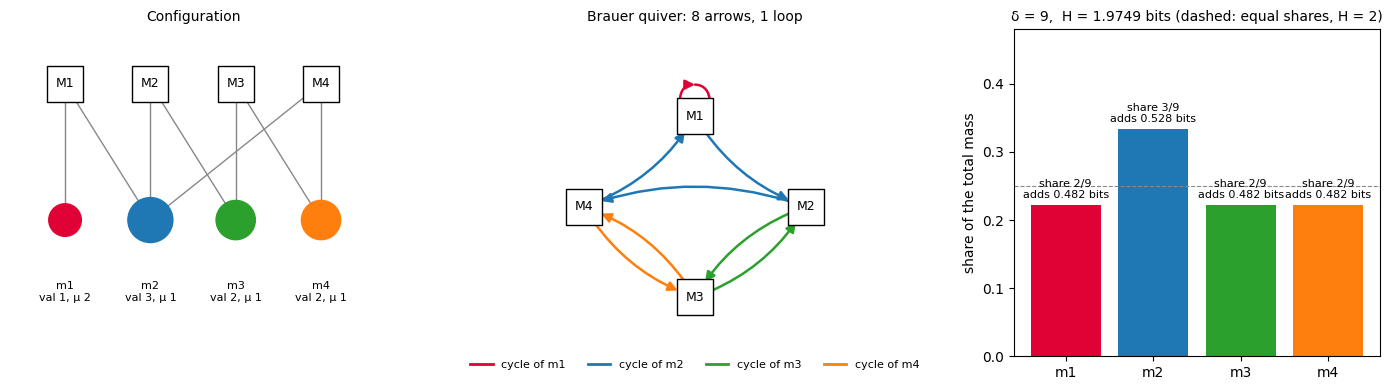

,lies in,val,μ,mass = μ·val,arrows it draws,adds to dim Λ: val·(μ·val − 1),share of the mass
vertex,,,,,,,
m1,M1,1,2,2,1,1,0.222
m2,"M1, M2, M4",3,1,3,3,6,0.333
m3,"M2, M3",2,1,2,2,2,0.222
m4,"M3, M4",2,1,2,2,2,0.222


arrows of the quiver = sum of 'arrows it draws' = 8
δ = sum of the masses = 9
dim Λ = 2 × 4 polygons + 11 = 19
H = 1.9749 bits. With 4 vertices the maximum is log2(4) = 2.0000, reached only if all the masses are equal
H, term by term: 0.4822 + 0.5283 + 0.4822 + 0.4822 = 1.9749
dim Λ = 2·(polygons) + Σ val·(μ·val − 1) = 2·4 + 1·(2·1 − 1) + 3·(1·3 − 1) + 2·(1·2 − 1) + 2·(1·2 − 1) = 19


In [ ]:
published_polygons = {"M1": ["m1", "m2"], "M2": ["m2", "m3"], "M3": ["m3", "m4"], "M4": ["m2", "m4"]}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
draw_configuration(published, published_polygons, ax1, "Configuration")
draw_brauer_quiver(published, {"M1": (0, 1), "M2": (1, 0), "M3": (0, -1), "M4": (-1, 0)}, ax2,
                   "Brauer quiver: 8 arrows, 1 loop")
shares = [m_ / delta for m_ in masses.values()]
bars = ax3.bar(list(masses), shares, color=VERTEX_COLORS[:4])
for bar, m_, p in zip(bars, masses.values(), shares):
    ax3.text(bar.get_x() + bar.get_width() / 2, p + 0.01,
             f"share {m_}/{delta}\nadds {-p * math.log2(p):.3f} bits", ha="center", fontsize=8)
ax3.axhline(0.25, color="#888888", ls="--", lw=0.8)
ax3.set_ylim(0, 0.48)
ax3.set_ylabel("share of the total mass")
ax3.set_title(f"δ = {delta},  H = {H:.4f} bits (dashed: equal shares, H = 2)", fontsize=10)
plt.tight_layout()
plt.show()

explain(published, published_polygons)
print("H, term by term:", " + ".join(f"{-p * math.log2(p):.4f}" for p in shares), f"= {H:.4f}")
print("dim Λ = 2·(polygons) + Σ val·(μ·val − 1) = 2·4 +",
      " + ".join(f"{published.valency(v)}·({published.mu(v)}·{published.valency(v)} − 1)" for v in masses),
      "=", 8 + sum(published.valency(v) * (published.mu(v) * published.valency(v) - 1) for v in masses))

### A basis, and what the entropy does not see

*Slides: "A basis of the four-polygon algebra" and "What the entropy does not see".*

**A basis with 19 elements.**

| Kind of element | Which ones | How many |
|---|---|---|
| trivial paths | one per polygon | 4 |
| arrows | $\ell, a, b, c, d, e, f, g$ | 8 |
| unfinished turns of length two | $ab$, $bc$, $ca$, in the cycle of $m_2$ | 3 |
| complete turns | one class per polygon: $\ell^2 = abc$, $bca = de$, $ed = fg$, $cab = gf$ | 4 |

$4 + 8 + 3 + 4 = 19$. The square $\ell^2$ is not an extra element, because it equals $abc$. The formula gives the same number: $2 \cdot 4 + (1 \cdot 1 + 3 \cdot 2 + 2 \cdot 1 + 2 \cdot 1) = 8 + 11 = 19$.

**The centre.** A basis is the unit, the four complete turns and the loop $\ell$: dimension 6.

**What $H$ does not see.** $H$ is computed from the masses only. So two changes leave it where it was: multiplying every mass by the same factor, and choosing another cyclic order at a vertex. The second one changes the quiver. **Predict** what happens to $H$, to the arrows and to $\dim \Lambda$, then run the cell.

In [24]:
def entropy(values):
    total = sum(values)
    return -sum(v / total * math.log2(v / total) for v in values)


m = list(masses.values())
print("masses", m, "-> H =", round(entropy(m), 4))
print("every mass times 3 -> H =", round(entropy([3 * v for v in m]), 4))

# The same polygons with the cycle of m2 reversed. The package orders the polygons by name,
# so we rename them: N2 is the old M4 and N4 is the old M2. The cycle of m2 is now M1 -> M4 -> M2 -> M1.
reordered = BrauerConfiguration(
    vertices=["m1", "m2", "m3", "m4"],
    polygons={"N1": ["m1", "m2"], "N2": ["m2", "m4"], "N3": ["m3", "m4"], "N4": ["m2", "m3"]},
    mu={"m1": 2, "m2": 1, "m3": 1, "m4": 1})
successors(reordered)
pd.DataFrame([report(published, "published order"), report(reordered, "another cyclic order")])

masses [2, 3, 2, 2] -> H = 1.9749
every mass times 3 -> H = 1.9749
  m1: val = 1, μ = 2, cycle N1 → N1
  m2: val = 3, μ = 1, cycle N1 → N2 → N4 → N1
  m3: val = 2, μ = 1, cycle N3 → N4 → N3
  m4: val = 2, μ = 1, cycle N2 → N3 → N2


,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,published order,4,4,8,1,19,6,9,1.9749,2.0
1,another cyclic order,4,4,8,1,19,6,9,1.9749,2.0


The cycle of $m_2$ now runs the other way, and the numbers of the table did not change: they only depend on the valencies and the multiplicities. $\delta$ is the total mass, a size. It is not an indicator of quality or of causal impact, and neither $H$ nor $\delta$ determines the algebra.

#### Try it: move the masses

Four vertices, four masses. The bars are the probabilities. **Find:** the masses that give exactly 2 bits, and a choice that brings the entropy below 1.5 bits.

In [ ]:
def explore_entropy(m1=2, m2=3, m3=2, m4=2):
    values = [m1, m2, m3, m4]
    total = sum(values)
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(["m1", "m2", "m3", "m4"], [v / total for v in values], color="#E00234")
    ax.axhline(0.25, color="#888888", lw=0.8, ls="--")
    ax.set_ylim(0, 1)
    ax.set_ylabel("probability")
    ax.set_title(f"δ = {total}    H = {entropy(values):.4f} bits    maximum 2")
    plt.show()


interact(explore_entropy, m1=(1, 20), m2=(1, 20), m3=(1, 20), m4=(1, 20));

### 4.3 A corpus of articles as a configuration

Take articles $P_1, \dots, P_h$ in chronological order, each with its list of references.

| Datum | In a bibliography |
|---|---|
| $\Gamma_0$ | the references cited by at least one article |
| $\Gamma_1$ | the articles: each one is the polygon formed by its references |
| $\mu$ | 2 if the reference is cited once, 1 otherwise |
| $\mathcal{O}$ | chronological order of the citing articles |

**The valency** of a reference is the number of times the corpus cites it.

**The multiplicity rule is a convention of this model.** It is the smallest choice that leaves no truncated vertex: a reference cited once gets $\mu = 2$, so it still draws a loop at its only article instead of disappearing from the quiver.

**What the arrows mean.** Around each reference, an arrow goes from each article to the next one that cites it, and one arrow goes from the last article back to the first. That last arrow closes the cycle that the algebra needs. It is not a citation and it does not mean propagation into the past. In fact no arrow of this quiver says that one article cites another: every arrow joins two articles that share a reference.

**Shortcuts for a corpus.** If no article repeats a reference, call $S$ the total number of citations and $C$ the set of references cited once. Then:

| Quantity | Formula |
|---|---|
| arrows | $S$ |
| loops | $\lvert C \rvert$ |
| $\delta$ | $S + \lvert C \rvert$ |
| $\dim \Lambda$ | $2h + \lvert C \rvert + \sum_{\mathrm{val}(r) \ge 2} \mathrm{val}(r)\,(\mathrm{val}(r) - 1)$ |
| $\dim Z(\Lambda)$ | $1 + h + \lvert C \rvert$ (connected, reduced corpus) |

**Exercise, by hand first.** Three articles in chronological order, five references:

$$P_1 = \{a, b, c\}, \qquad P_2 = \{b, c, d\}, \qquad P_3 = \{a, c, e\}$$

Find val and μ, the cycle of each reference, the number of arrows and loops, $\dim \Lambda$, $\dim Z(\Lambda)$, δ and $H$.

<details><summary>Solution (open after trying)</summary>

| Reference | Cited by | val | μ | Mass | Its cycle |
|---|---|---|---|---|---|
| $a$ | $P_1, P_3$ | 2 | 1 | 2 | $P_1 \to P_3 \to P_1$ |
| $b$ | $P_1, P_2$ | 2 | 1 | 2 | $P_1 \to P_2 \to P_1$ |
| $c$ | $P_1, P_2, P_3$ | 3 | 1 | 3 | $P_1 \to P_2 \to P_3 \to P_1$ |
| $d$ | $P_2$ | 1 | 2 | 2 | loop at $P_2$ |
| $e$ | $P_3$ | 1 | 2 | 2 | loop at $P_3$ |

With $h = 3$, $S = 9$ and $\lvert C \rvert = 2$: 9 arrows, 2 of them loops; $\delta = 9 + 2 = 11$; $\dim \Lambda = 6 + 2 + (2 + 2 + 6) = 18$; $\dim Z(\Lambda) = 1 + 3 + 2 = 6$. The entropy is $H = 4 \cdot \tfrac{2}{11}\log_2\tfrac{11}{2} + \tfrac{3}{11}\log_2\tfrac{11}{3} \approx 2.2999$ bits, out of a maximum of $\log_2 5 \approx 2.3219$.

Notice the two arrows from $P_1$ to $P_2$: one is drawn by $b$ and the other by $c$. Same start, same end, different reason.

</details>

In [21]:
toy = BrauerConfiguration(
    vertices=["a", "b", "c", "d", "e"],
    polygons={"P1": ["a", "b", "c"],
              "P2": ["b", "c", "d"],
              "P3": ["a", "c", "e"]})

toy.brauer_analysis()

{'n_vertices': 5,
 'n_polygons': 3,
 'dimension': 18,
 'center_dimension': 6,
 'n_loops': 2,
 'defect': 0,
 'impact_factor_delta_B': 11,
 'entropy_H_B': 2.299896391167891,
 'valencies': {'a': 2, 'b': 2, 'c': 3, 'd': 1, 'e': 1},
 'multiplicities': {'a': 1, 'b': 1, 'c': 1, 'd': 2, 'e': 2},
 'truncated_vertices': [],
 'univalent_vertices': ['d', 'e'],
 'multivalent_vertices': ['a', 'b', 'c']}

  a: val = 2, μ = 1, cycle P1 → P3 → P1
  b: val = 2, μ = 1, cycle P1 → P2 → P1
  c: val = 3, μ = 1, cycle P1 → P2 → P3 → P1
  d: val = 1, μ = 2, cycle P2 → P2
  e: val = 1, μ = 2, cycle P3 → P3


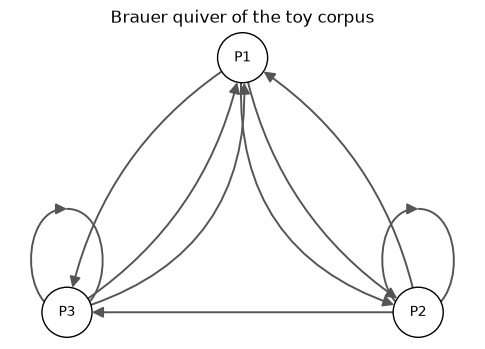

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,toy corpus,3,5,9,2,18,6,11,2.2999,2.3219


In [22]:
successors(toy)
draw_quiver(toy.brauer_quiver(), {"P1": (0, 1), "P2": (1.2, -0.6), "P3": (-1.2, -0.6)},
            "Brauer quiver of the toy corpus", labels=False, node_size=1300)
pd.DataFrame([report(toy, "toy corpus")])

#### Picture: three articles and five references

Squares are the articles $P_1, P_2, P_3$; circles are the references they cite, larger when cited more often. The reference $c$ is cited by all three, and $d$ and $e$ by only one. The bars on the right are the masses that enter $\delta$ and $H$.

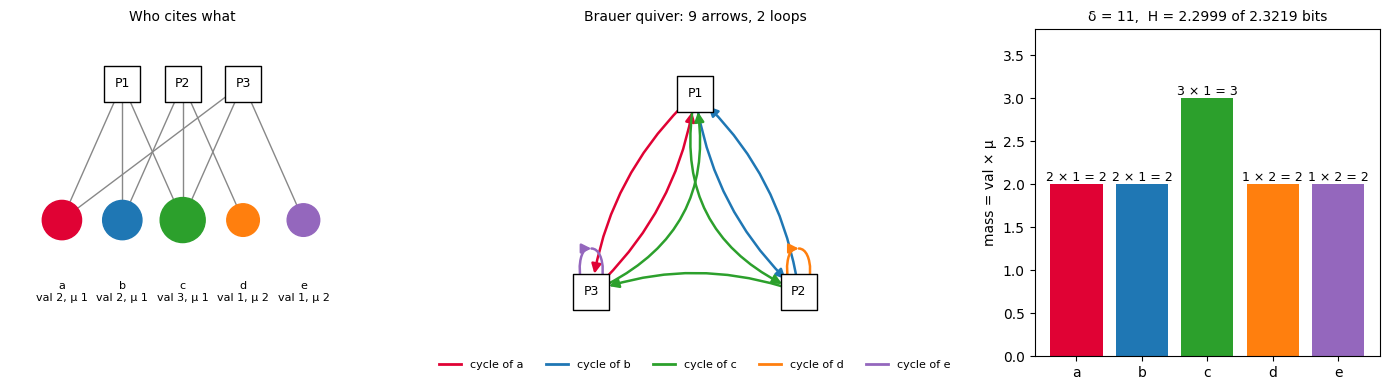

,lies in,val,μ,mass = μ·val,arrows it draws,adds to dim Λ: val·(μ·val − 1),share of the mass
vertex,,,,,,,
a,"P1, P3",2,1,2,2,2,0.182
b,"P1, P2",2,1,2,2,2,0.182
c,"P1, P2, P3",3,1,3,3,6,0.273
d,P2,1,2,2,1,1,0.182
e,P3,1,2,2,1,1,0.182


arrows of the quiver = sum of 'arrows it draws' = 9
δ = sum of the masses = 11
dim Λ = 2 × 3 polygons + 12 = 18
H = 2.2999 bits. With 5 vertices the maximum is log2(5) = 2.3219, reached only if all the masses are equal


In [ ]:
toy_polygons = {"P1": ["a", "b", "c"], "P2": ["b", "c", "d"], "P3": ["a", "c", "e"]}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
draw_configuration(toy, toy_polygons, ax1, "Who cites what")
draw_brauer_quiver(toy, {"P1": (0, 1), "P2": (1.2, -0.6), "P3": (-1.2, -0.6)}, ax2,
                   "Brauer quiver: 9 arrows, 2 loops")
toy_masses = {v: toy.mu(v) * toy.valency(v) for v in toy.Gamma0}
bars = ax3.bar(list(toy_masses), list(toy_masses.values()), color=VERTEX_COLORS[:5])
ax3.bar_label(bars, labels=[f"{toy.valency(v)} × {toy.mu(v)} = {m_}" for v, m_ in toy_masses.items()],
              fontsize=9)
ax3.set_ylim(0, 3.8)
ax3.set_ylabel("mass = val × μ")
ax3.set_title(f"δ = {sum(toy_masses.values())},  H = {entropy(toy_masses.values()):.4f} of "
              f"{math.log2(5):.4f} bits", fontsize=10)
plt.tight_layout()
plt.show()
explain(toy, toy_polygons)

**Now change one reference list and predict the new values before you run the cell.** For instance, what happens if $P_3$ also cites $b$?

In [23]:
toy2 = BrauerConfiguration(
    vertices=["a", "b", "c", "d", "e"],
    polygons={"P1": ["a", "b", "c"],
              "P2": ["b", "c", "d"],
              "P3": ["a", "b", "c", "e"]})   # edit this line
pd.DataFrame([report(toy, "toy corpus"), report(toy2, "edited")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,toy corpus,3,5,9,2,18,6,11,2.2999,2.3219
1,edited,3,5,10,2,22,6,12,2.2925,2.3219


### Two edits, two different answers

*Slide: "Two edits to the toy corpus".*

Now let $P_3$ also cite $d$ instead of $b$. The valency of $d$ goes from 1 to 2, so the multiplicity rule lowers $\mu(d)$ from 2 to 1. **Predict which columns move.**

In [28]:
toy3 = BrauerConfiguration(
    vertices=["a", "b", "c", "d", "e"],
    polygons={"P1": ["a", "b", "c"],
              "P2": ["b", "c", "d"],
              "P3": ["a", "c", "d", "e"]})
pd.DataFrame([report(toy, "original"), report(toy2, "P3 also cites b"), report(toy3, "P3 also cites d")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,original,3,5,9,2,18,6,11,2.2999,2.3219
1,P3 also cites b,3,5,10,2,22,6,12,2.2925,2.3219
2,P3 also cites d,3,5,10,1,19,5,11,2.2999,2.3219


#### Picture: the two edits, side by side

The same three articles, with one reference added to $P_3$ in the middle and right drawings. Below, the numbers of the table as bars: look at which bars move with each edit.

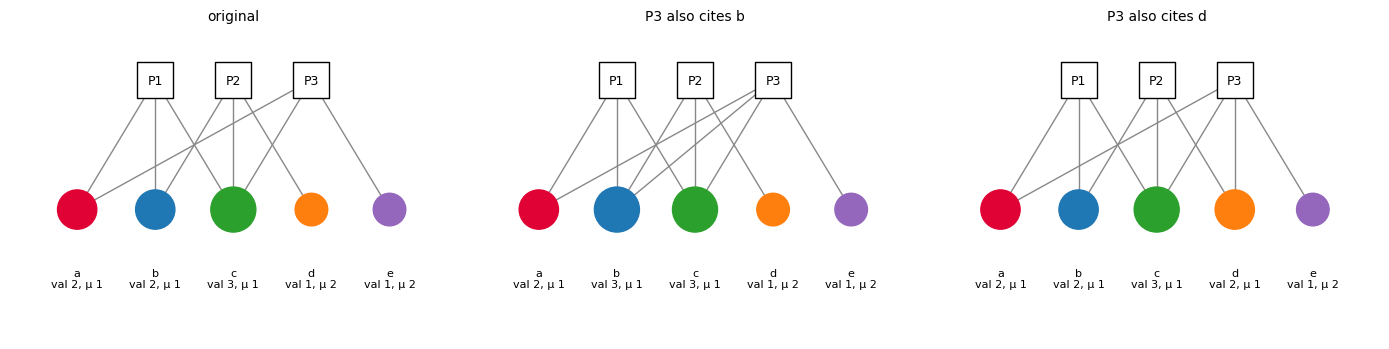

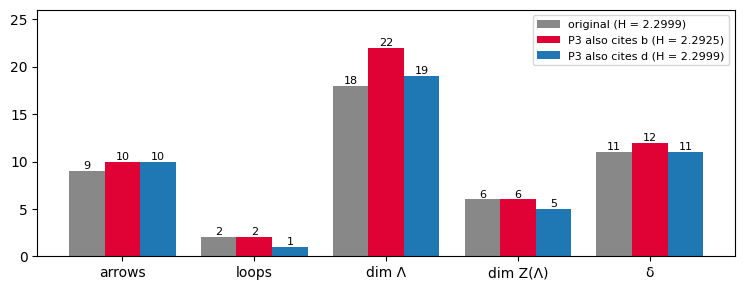

In [ ]:
versions = [("original", toy, toy_polygons),
            ("P3 also cites b", toy2, {**toy_polygons, "P3": ["a", "b", "c", "e"]}),
            ("P3 also cites d", toy3, {**toy_polygons, "P3": ["a", "c", "d", "e"]})]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (label, bc, polygons_) in zip(axes, versions):
    draw_configuration(bc, polygons_, ax, label)
plt.tight_layout()
plt.show()

quantities = ["arrows", "loops", "dim Λ", "dim Z(Λ)", "δ"]
fig, ax = plt.subplots(figsize=(9, 3.2))
for k, ((label, bc, _), color) in enumerate(zip(versions, ["#888888", "#E00234", "#1F77B4"])):
    r = report(bc)
    bars = ax.bar([i + (k - 1) * 0.27 for i in range(len(quantities))], [r[q] for q in quantities],
                  width=0.27, color=color, label=f"{label} (H = {r['H (bits)']})")
    ax.bar_label(bars, fontsize=8)
ax.set_xticks(range(len(quantities)), quantities)
ax.set_ylim(0, 26)
ax.legend(fontsize=8)
plt.show()

**Why the two edits behave differently.**

- *$P_3$ also cites $b$.* The reference $b$ was already shared. Its valency goes from 2 to 3, its multiplicity stays at 1 and its mass goes from 2 to 3: $\delta$ grows to 12 and $H$ moves. Its part of the dimension goes from $2\,(2 - 1) = 2$ to $3\,(3 - 1) = 6$, so $\dim \Lambda$ goes from 18 to 22. No loop appears or disappears, and the centre stays at 6.
- *$P_3$ also cites $d$.* The valency of $d$ goes from 1 to 2, and the multiplicity rule lowers $\mu(d)$ from 2 to 1: its mass is still 2, so $\delta$ and $H$ do not move. But the loop at $P_2$ becomes a cycle of two arrows between $P_2$ and $P_3$: $\dim \Lambda$ goes to 19 and the centre drops to 5.

One more citation does not always change the entropy: $H$ reads how the masses are distributed, and the algebra also sees which paths exist. The graph of pairs of articles is a triangle in the three cases.

Before comparing real corpora one has to justify the document unit, the time window, how references are deduplicated and the multiplicity rule. The chronological order used here gives no transition rules and no causality.

#### Try it: write your own three articles

Type the references of each article, separated by commas, and press Enter. The table compares your corpus with the original one and the quiver is redrawn. **Try:** make every article cite the same three references; then make no two articles share a reference.

In [ ]:
def edit_corpus(P1="a, b, c", P2="b, c, d", P3="a, c, e"):
    polygons = {name: sorted({r.strip() for r in text.split(",") if r.strip()})
                for name, text in (("P1", P1), ("P2", P2), ("P3", P3))}
    if any(len(refs) < 2 for refs in polygons.values()):
        print("Each article needs at least two different references.")
        return
    vertices = sorted({r for refs in polygons.values() for r in refs})
    try:
        yours = BrauerConfiguration(vertices=vertices, polygons=polygons)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
        draw_configuration(yours, polygons, ax1, "Your corpus: who cites what")
        draw_brauer_quiver(yours, {"P1": (0, 1), "P2": (1.2, -0.6), "P3": (-1.2, -0.6)}, ax2,
                           "Brauer quiver of your corpus")
        plt.tight_layout()
        plt.show()
        successors(yours)
        display(pd.DataFrame([report(toy, "original"), report(yours, "yours")]))
    except Exception as error:
        print("This corpus is not a valid configuration:", error)


interact(edit_corpus, P1=Text(value="a, b, c", continuous_update=False),
         P2=Text(value="b, c, d", continuous_update=False), P3=Text(value="a, c, e", continuous_update=False));

<details><summary>What to notice (open after trying)</summary>

If the three articles cite the same three references, every reference has valency 3 and mass 3: the entropy is at its maximum, $\log_2 3$, and there are no loops. If no two articles share a reference, every reference is cited once, so every arrow is a loop and the three articles are disconnected in the quiver.

</details>

#### Check yourself

In [ ]:
check("arrows of the four-polygon quiver", ...)
check("dimension of the four-polygon algebra", ...)
check("dimension of the centre when P3 also cites d", ...)

### 4.4 Simulated corpora

We now build corpora instead of collecting them. Every corpus has 60 articles with 12 different references each, so the total is always $60 \times 12 = 720$ citations. Each article chooses its references one by one: with probability `p_new` it cites a reference nobody has cited before, otherwise it cites an existing reference, chosen in proportion to the citations that reference already has.

- **Large `p_new`**: every article brings its own bibliography. Many references, almost all cited once.
- **Small `p_new`**: the corpus keeps returning to the same sources. Few references, cited many times.

The data are simulated. The numbers describe the generator and its seed, and they are not a statement about any real author or field.

In [24]:
def simulate_corpus(n_articles=60, refs_per_article=12, p_new=0.5, seed=0):
    # A simulated corpus: article -> list of distinct references, in chronological order.
    rng = np.random.default_rng(seed)
    citations = []                # citations[r] = number of times reference r has been cited
    polygons = {}
    for k in range(n_articles):
        chosen = set()
        while len(chosen) < refs_per_article:
            free = [r for r in range(len(citations)) if r not in chosen]
            if not free or rng.random() < p_new:
                citations.append(0)
                r = len(citations) - 1
            else:
                weights = np.array([citations[x] for x in free], dtype=float)
                r = free[rng.choice(len(free), p=weights / weights.sum())]
            chosen.add(r)
        for r in chosen:
            citations[r] += 1
        polygons[f"P{k + 1:03d}"] = [f"r{r}" for r in sorted(chosen)]
    vertices = [f"r{r}" for r in range(len(citations))]
    years = {name: {"year": 2000 + i} for i, name in enumerate(polygons)}
    return BrauerConfiguration(vertices=vertices, polygons=polygons, polygon_data=years)


corpus = simulate_corpus(p_new=0.5, seed=0)
pd.DataFrame([report(corpus, "simulated, p_new = 0.5")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,"simulated, p_new = 0.5",60,333,720,218,3776,279,938,8.0524,8.3794


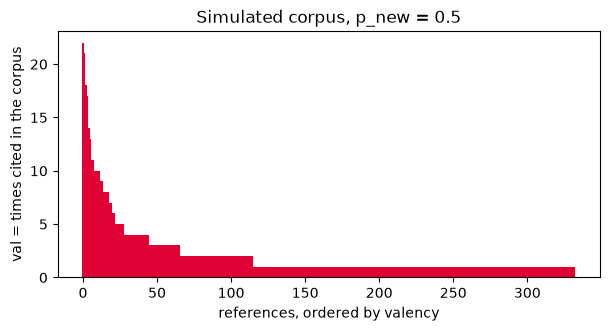

cited once: 218 of 333 references


In [25]:
valencies = sorted((corpus.valency(v) for v in corpus.Gamma0), reverse=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(valencies)), valencies, color="#E00234", width=1.0)
ax.set_xlabel("references, ordered by valency")
ax.set_ylabel("val = times cited in the corpus")
ax.set_title("Simulated corpus, p_new = 0.5")
plt.show()
print("cited once:", sum(v == 1 for v in valencies), "of", len(valencies), "references")

### Several simulated corpora

**Predict first:** as `p_new` goes down, what happens to the number of references, to $\dim \Lambda$ and to $H$ compared with its maximum $\log_2 |\Gamma_0|$?

In [26]:
rows = []
for p_new in (0.9, 0.7, 0.5, 0.3, 0.1, 0.02):
    r = report(simulate_corpus(p_new=p_new, seed=0), f"p_new = {p_new}")
    r["H / max"] = round(r["H (bits)"] / r["log2 |Γ0|"], 3)
    rows.append(r)
table = pd.DataFrame(rows).set_index("configuration").drop(columns=["arrows", "loops"])
table

,polygons,vertices,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|,H / max
configuration,,,,,,,,
p_new = 0.9,60,648,896,653,1312,9.3348,9.3399,0.999
p_new = 0.7,60,482,1534,429,1088,8.8320,8.9129,0.991
p_new = 0.5,60,333,3776,279,938,8.0524,8.3794,0.961
p_new = 0.3,60,220,6632,189,848,7.1985,7.7814,0.925
p_new = 0.1,60,74,20899,98,757,5.1762,6.2095,0.834
p_new = 0.02,60,31,34177,68,727,4.1241,4.9542,0.832


#### Picture: the table as curves

From left to right the field goes from "every article brings new references" (p_new = 0.9) to "everybody cites the same classics" (p_new = 0.02). The number of references falls, the dimension of the algebra grows, and the entropy moves away from its maximum.

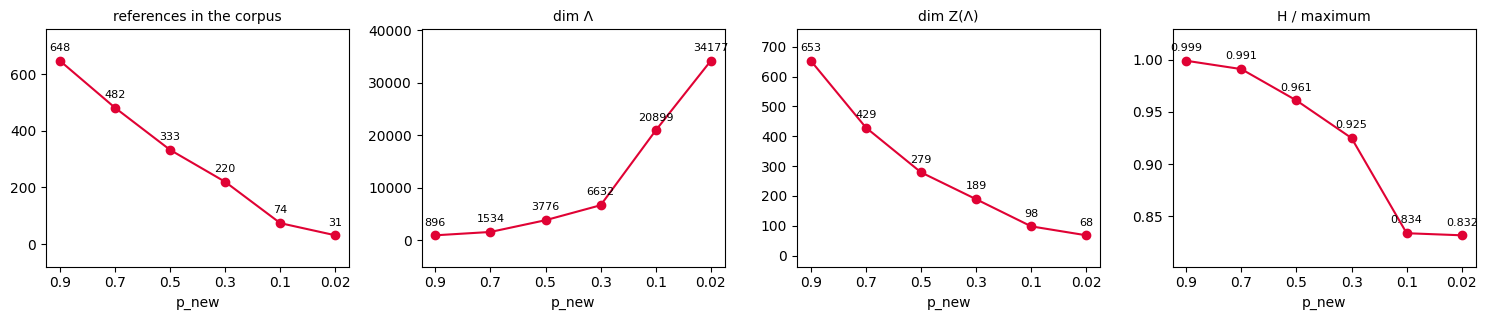

In [ ]:
p_values = [0.9, 0.7, 0.5, 0.3, 0.1, 0.02]
labels_ = [str(p) for p in p_values]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, column, title in zip(axes, ["vertices", "dim Λ", "dim Z(Λ)", "H / max"],
                             ["references in the corpus", "dim Λ", "dim Z(Λ)", "H / maximum"]):
    ax.plot(labels_, table[column].values, "o-", color="#E00234")
    for x, y in zip(labels_, table[column].values):
        ax.annotate(y, (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("p_new")
    ax.margins(y=0.18)
plt.tight_layout()
plt.show()

#### Try it: slide between the two kinds of field

Move `p_new` from "every article brings its own references" (right) to "everybody cites the same classics" (left). The bars are the valencies of the references, from the most cited to the least. **Watch:** the shape of the bars, the dimension, and how far the entropy is from its maximum.

In [ ]:
def explore_corpus(p_new=0.5, n_articles=60):
    simulated = simulate_corpus(n_articles=n_articles, p_new=p_new, seed=0)
    r = report(simulated)
    valencies_ = sorted((simulated.valency(v) for v in simulated.Gamma0), reverse=True)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(range(len(valencies_)), valencies_, color="#E00234", width=1.0)
    ax.set_xlabel("references, ordered by valency")
    ax.set_ylabel("times cited")
    ax.set_title(f"p_new = {p_new}: {r['vertices']} references, dim Λ = {r['dim Λ']}, "
                 f"H / max = {r['H (bits)'] / r['log2 |Γ0|']:.3f}")
    plt.show()


interact(explore_corpus, p_new=FloatSlider(value=0.5, min=0.02, max=0.9, step=0.04, continuous_update=False),
         n_articles=IntSlider(value=60, min=20, max=100, step=20, continuous_update=False));

**What the table shows.** Between the first row and the last one not a single citation was added: only the reuse grew, and fewer references collected the same 720 citations.

- The number of references falls from 648 to 31.
- $\dim \Lambda$ grows from 896 to 34177. With multiplicity one, a reference adds $\mathrm{val}(r)\,(\mathrm{val}(r) - 1)$, which grows with the square of the valency: one reference cited 20 times adds 380, and twenty references cited once add 20.
- $H$ goes down, but so does its maximum, because there are fewer references to share the mass. The ratio `H / max` separates the two effects: it goes from almost 1 to about 0.83.

**Check one row with the shortcuts.** For `p_new = 0.5` there are 333 references and 218 of them are cited once. Then $\delta = 720 + 218 = 938$ and $\dim Z(\Lambda) = 1 + 60 + 218 = 279$, the values of the table.

**Discuss.**

- Why does $\dim \Lambda$ grow when the corpus has fewer references?
- $H$ stays close to its maximum in most rows. What would a corpus with low $H$ look like? Try to build one by editing `simulate_corpus` or by writing the polygons yourself.
- Which of these readings are properties of the construction, and which would be claims about a research community?

In [27]:
# Your corpus. Example: every article cites the same core, plus one reference of its own.
core = [f"core{i}" for i in range(3)]
own = [f"own{k}" for k in range(20)]
star = BrauerConfiguration(vertices=core + own,
                           polygons={f"P{k + 1:02d}": core + [own[k]] for k in range(20)})
pd.DataFrame([report(star, "shared core + one own reference")])

,configuration,polygons,vertices,arrows,loops,dim Λ,dim Z(Λ),δ,H (bits),log2 |Γ0|
0,shared core + one own reference,20,23,80,20,1200,41,100,3.6507,4.5236


#### Picture: the same idea with five articles

The example above has 20 articles; this is the same construction with 5, small enough to draw. Every article cites the three core references and one of its own.

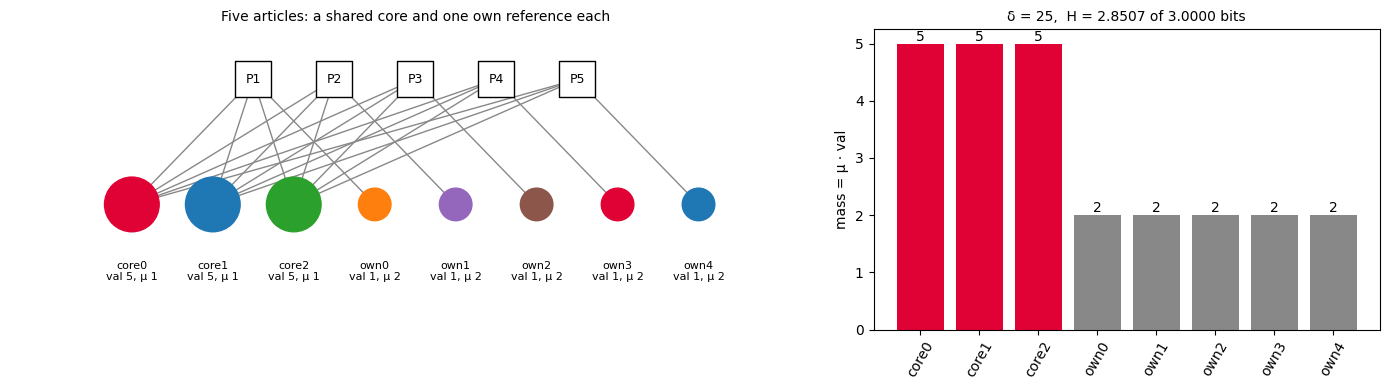

,lies in,val,μ,mass = μ·val,arrows it draws,adds to dim Λ: val·(μ·val − 1),share of the mass
vertex,,,,,,,
core0,"P1, P2, P3, P4, P5",5,1,5,5,20,0.20
core1,"P1, P2, P3, P4, P5",5,1,5,5,20,0.20
core2,"P1, P2, P3, P4, P5",5,1,5,5,20,0.20
own0,P1,1,2,2,1,1,0.08
own1,P2,1,2,2,1,1,0.08
own2,P3,1,2,2,1,1,0.08
own3,P4,1,2,2,1,1,0.08
own4,P5,1,2,2,1,1,0.08


arrows of the quiver = sum of 'arrows it draws' = 20
δ = sum of the masses = 25
dim Λ = 2 × 5 polygons + 65 = 75
H = 2.8507 bits. With 8 vertices the maximum is log2(8) = 3.0000, reached only if all the masses are equal


In [ ]:
core5 = ["core0", "core1", "core2"]
star5_polygons = {f"P{k + 1}": core5 + [f"own{k}"] for k in range(5)}
star5 = BrauerConfiguration(vertices=core5 + [f"own{k}" for k in range(5)], polygons=star5_polygons)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
draw_configuration(star5, star5_polygons, ax1, "Five articles: a shared core and one own reference each")
star5_masses = {v: star5.mu(v) * star5.valency(v) for v in star5.Gamma0}
bars = ax2.bar(list(star5_masses), list(star5_masses.values()),
               color=["#E00234"] * 3 + ["#888888"] * 5)
ax2.bar_label(bars)
ax2.tick_params(axis="x", labelrotation=60)
ax2.set_ylabel("mass = μ · val")
ax2.set_title(f"δ = {sum(star5_masses.values())},  H = {entropy(star5_masses.values()):.4f} of "
              f"{math.log2(8):.4f} bits", fontsize=10)
plt.tight_layout()
plt.show()
explain(star5, star5_polygons)

<a id="5"></a>
## 5. Optional extension: train the three operators

*Slide: "Walk Attention". This part is not needed for the workshop exercises.*

Three models on one synthetic long-range retrieval task (a bottleneck with $K = 5$ sources, so chance is 0.20): **GAT** (one hop, learned weights), a **walk operator** (multi-hop, fixed weights) and **Walk Attention** (multi-hop, learned weights). It installs PyTorch Geometric and the `oversquash` package from the paper's repository, and takes about one or two minutes on CPU.

This is one small run with one seed. Read it as a demonstration, not as a replication of the results in the paper.

In [28]:
!pip install -q torch_geometric "git+https://github.com/Izainea/path-algebra-gnn"

In [29]:
# Train the three models on the bottleneck retrieval task (small, fast version).
import torch, torch.nn.functional as F, numpy as np, math
from torch.utils.data import DataLoader
from torch_geometric.loader import DataLoader as PyGLoader
from oversquash.data_bottleneck import make_bottleneck_graph
from oversquash.transforms import (AttachWalkMasks, collate_walk_masks,
                                   AttachWalkOperators, collate_walk_operators)
from oversquash.models import build_model
K, M, DEPTH = 5, 4, 3   # chance = 1/5 = 0.20
def ds(seed, n=1500):
    g = torch.Generator().manual_seed(seed)
    return [make_bottleneck_graph(K, M, DEPTH, g) for _ in range(n)]

def train_eval(m, tr, va, fwd, epochs=70, lr=2e-3, warmup=8):
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e+1)/warmup if e<warmup
                                            else 0.5*(1+math.cos(math.pi*(e-warmup)/max(1,epochs-warmup))))
    best = 0.0
    for e in range(epochs):
        m.train()
        for b in tr:
            opt.zero_grad(); lg,_ = fwd(m,b)
            F.cross_entropy(lg, b.y, ignore_index=-100).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        sch.step(); m.eval(); a=[]
        with torch.no_grad():
            for b in va:
                lg,_ = fwd(m,b); mm=b.root_mask
                a.append((lg[mm].argmax(-1)==b.y[mm]).float().mean().item())
        best = max(best, float(np.mean(a)))
    return best

def run(name, seed=0):
    torch.manual_seed(seed); data = ds(seed); nl = DEPTH+1
    if name=='gat':
        tr=PyGLoader(data[:1200],batch_size=128,shuffle=True); va=PyGLoader(data[1200:],batch_size=128)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None))
    elif name=='walkraw':
        tf=AttachWalkOperators(n_layers=nl); data=[tf(d) for d in data]
        tr=DataLoader(data[:1200],batch_size=128,shuffle=True,collate_fn=collate_walk_operators)
        va=DataLoader(data[1200:],batch_size=128,collate_fn=collate_walk_operators)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None),walk_raw=b.walk_raw)
    else:
        tf=AttachWalkMasks(n_layers=nl); data=[tf(d) for d in data]
        tr=DataLoader(data[:1200],batch_size=128,shuffle=True,collate_fn=collate_walk_masks)
        va=DataLoader(data[1200:],batch_size=128,collate_fn=collate_walk_masks)
        fwd=lambda m,b: m(b.x,b.edge_index,getattr(b,'batch',None),walk_masks=b.walk_masks)
    m = build_model(name, data[0].x.size(-1), 16, data[0].num_classes, nl, heads=4)
    return train_eval(m, tr, va, fwd)

labels = {'gat': 'GAT (1 hop, learned weights)',
          'walkraw': 'Walk operator (multi-hop, fixed weights)',
          'walkattn': 'Walk Attention (multi-hop, learned weights)'}
for name, label in labels.items():
    print(f'{label:44s} accuracy = {run(name):.3f}')

GAT (1 hop, learned weights)                 accuracy = 0.208


Walk operator (multi-hop, fixed weights)     accuracy = 0.398


Walk Attention (multi-hop, learned weights)  accuracy = 1.000


<a id="6"></a>
## 6. The same checks in plain Python

This cell uses only the standard library. It repeats the propagation of section 1 and the toy corpus of section 4.3 without the package, so you can check both even without Colab.

In [34]:
from collections import Counter
from math import log2

toy_arrows = [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("D", "E"), ("E", "F")]


def spread_plain(edges, seed):
    active = {seed}
    history = [sorted(active)]
    while True:
        updated = active | {v for u, v in edges if u in active}
        if updated == active:
            return history
        active = updated
        history.append(sorted(active))


cut_arrows = [edge for edge in toy_arrows if edge != ("D", "E")]
print("with the bridge:   ", spread_plain(toy_arrows, "A")[-1])
print("without the bridge:", spread_plain(cut_arrows, "A")[-1])

base = [{"a", "b", "c"}, {"b", "c", "d"}, {"a", "c", "e"}]


def mass_entropy_dimension(corpus):
    val = Counter(x for article in corpus for x in article)
    mu = {x: 2 if v == 1 else 1 for x, v in val.items()}
    masses_ = {x: mu[x] * v for x, v in val.items()}
    delta_ = sum(masses_.values())
    H_ = -sum((w / delta_) * log2(w / delta_) for w in masses_.values())
    dim_ = 2 * len(corpus) + sum(v * (masses_[x] - 1) for x, v in val.items())
    return delta_, round(H_, 4), dim_


print("original:       ", mass_entropy_dimension(base))
print("P3 also cites b:", mass_entropy_dimension(base[:2] + [base[2] | {"b"}]))
print("P3 also cites d:", mass_entropy_dimension(base[:2] + [base[2] | {"d"}]))

with the bridge:    ['A', 'B', 'C', 'D', 'E', 'F']
without the bridge: ['A', 'B', 'C', 'D']
original:        (11, 2.2999, 18)
P3 also cites b: (12, 2.2925, 22)
P3 also cites d: (11, 2.2999, 19)


## Two uses of quivers

| Structure | Dynamics |
|---|---|
| Brauer configurations | Impact automata and Walk Attention |
| Combinatorial data, a cyclic order and multiplicities determine an algebra. | States change on a fixed quiver, and walks decide which nodes exchange information. |
| configuration → $KQ/I$ | paths → influence → update |

**Final activity.** In pairs, sketch a small applied problem: define the vertices and arrows, choose a structural or a dynamic question, give one path, one rule and one test, and state what would falsify your interpretation. No personal data.

---

Package: `pip install aiq-quivers` · Source: [github.com/Izainea/aiq-quivers](https://github.com/Izainea/aiq-quivers) and [github.com/Izainea/path-algebra-gnn](https://github.com/Izainea/path-algebra-gnn)

References: Green and Schroll, *Bull. Sci. Math.* 141 (2017) · Sierra, *J. Algebra* 510 (2018) · Moreno Cañadas et al., *Electron. Res. Arch.* 32(10) (2024) · Zainea Maya and Moreno Cañadas, CIARP 2026, LNCS, Springer.